# Employee Attrition Early Warning with Responsible Machine Learning

**Author:** Violetta Kalinicheva  
**Completed:** August 9, 2026  
**Portfolio revision:** October 2, 2026


## 1. Project Setup

This project examines whether workplace and employee characteristics can identify attrition risk early enough to support constructive retention conversations. I begin by importing the libraries used for data inspection, visualization, and modeling.


In [1]:
# Import pandas to load and work with the employee dataset
import pandas as pd

# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib and Seaborn for creating visualizations later in the project
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns so none of the employee variables are hidden
pd.set_option("display.max_columns", None)

# Use a clean visualization style for the graphs created later
sns.set_theme(style="whitegrid")

# Confirm that the libraries were imported successfully
print("The required libraries were imported successfully.")

The required libraries were imported successfully.


## Section 2: Loading the Dataset

Now that the required libraries have been imported, the next step is to load the employee attrition dataset into Python. Before beginning any analysis or data cleaning, it is important to verify that the dataset loads correctly and to inspect the first few records. This helps confirm that the data was imported successfully and provides an initial understanding of the variables that will be analyzed throughout the project.

In [2]:
# I load the source data before making any changes so I can verify its structure.
from pathlib import Path

data_path = Path("data/WA_Fn-UseC_-HR-Employee-Attrition.csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"The dataset was not found at {data_path.resolve()}. "
        "Download it from the Kaggle source linked in the README and place it in the data folder."
    )

df = pd.read_csv(data_path)

print("First five rows of the dataset:")
display(df.head())

print(f"\nNumber of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")


First five rows of the dataset:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2



Number of rows: 1470
Number of columns: 35


## Section 3: Initial Dataset Inspection

Before cleaning or analyzing the dataset, it is important to understand its overall structure. This step examines the column names, data types, and basic information about each variable. Understanding the dataset first helps identify potential issues such as incorrect data types, identifier columns, or variables that may require additional attention later in the analysis. Learning the structure of the data before making changes is an important best practice in data science because it prevents unnecessary assumptions and ensures that future preprocessing steps are based on evidence rather than guesswork.

In [3]:
# Display general information about the dataset
# I like doing this first because it gives me a quick overview
# of every column before I start cleaning anything.

print("=" * 80)
print("DATASET INFORMATION")
print("=" * 80)

df.info()

# Display every column name
print("\n" + "=" * 80)
print("COLUMN NAMES")
print("=" * 80)

for column in df.columns:
    print(column)

# Show the data types for each variable
print("\n" + "=" * 80)
print("DATA TYPES")
print("=" * 80)

display(df.dtypes.to_frame(name="Data Type"))

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobL

,Data Type
Age,int64
Attrition,object
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EmployeeCount,int64
EmployeeNumber,int64


### Interpretation

The initial inspection shows that the dataset loaded successfully and contains 1,470 employee records across 35 variables. The dataset includes a combination of 26 numerical variables and 9 categorical variables, providing information about employee demographics, job characteristics, compensation, work history, and employee satisfaction.

All 35 variables contain 1,470 non-null values, indicating that there are no missing values visible during the initial inspection. The target variable, Attrition, is stored as a categorical variable, making it appropriate for a binary classification problem. Overall, the dataset appears to be well structured and ready for a more detailed quality assessment, where duplicate records, constant features, unique identifiers, and other potential data quality issues will be evaluated before any cleaning or modeling begins.

## Section 4: Data Quality Assessment

Before exploring the data or building predictive models, it is important to evaluate the overall quality of the dataset. This step checks for missing values, duplicate records, constant features, and the number of unique values within each variable. Understanding these characteristics helps determine whether any cleaning or preprocessing is necessary and ensures that future analysis is based on reliable data.

In [4]:
# Check the overall quality of the dataset before making any changes.
# I want to understand if there are any issues that need to be fixed
# instead of assuming the data is already clean.

# -----------------------------
# Missing Values
# -----------------------------
missing_values = df.isnull().sum()

print("=" * 80)
print("MISSING VALUES")
print("=" * 80)
display(missing_values[missing_values > 0])

# -----------------------------
# Duplicate Records
# -----------------------------
duplicate_count = df.duplicated().sum()

print("\n" + "=" * 80)
print("DUPLICATE RECORDS")
print("=" * 80)
print(f"Number of duplicate rows: {duplicate_count}")

# -----------------------------
# Unique Values
# -----------------------------
unique_values = pd.DataFrame({
    "Unique Values": df.nunique()
}).sort_values(by="Unique Values")

print("\n" + "=" * 80)
print("NUMBER OF UNIQUE VALUES")
print("=" * 80)
display(unique_values)

# -----------------------------
# Constant Columns
# -----------------------------
constant_columns = unique_values[unique_values["Unique Values"] == 1]

print("\n" + "=" * 80)
print("CONSTANT FEATURES")
print("=" * 80)

if constant_columns.empty:
    print("No constant columns were found.")
else:
    display(constant_columns)

MISSING VALUES


Series([], dtype: int64)


DUPLICATE RECORDS
Number of duplicate rows: 0

NUMBER OF UNIQUE VALUES


,Unique Values
Over18,1
StandardHours,1
EmployeeCount,1
Gender,2
Attrition,2
PerformanceRating,2
OverTime,2
MaritalStatus,3
Department,3
BusinessTravel,3



CONSTANT FEATURES


,Unique Values
Over18,1
StandardHours,1
EmployeeCount,1


### Interpretation

The data quality assessment indicates that the dataset is in excellent condition. No missing values or duplicate records were identified, meaning no cleaning is required to address incomplete or repeated observations.

The assessment also identified three constant features: EmployeeCount, Over18, and StandardHours. Because these variables contain the same value for every employee, they do not provide useful information for predicting employee attrition and can be removed during preprocessing. Additionally, EmployeeNumber contains a unique value for every employee, suggesting that it functions as an identifier rather than a meaningful predictive feature. This will be verified before it is removed from the dataset.

## Section 5: Data Cleaning

Based on the data quality assessment, only a small amount of cleaning is required. The dataset does not contain missing values or duplicate records, so no observations need to be removed or imputed. The only preprocessing performed at this stage is the removal of features that provide no predictive value because they either contain a constant value or serve only as unique identifiers.

In [5]:
# Make a copy of the original dataset before cleaning.
# I like keeping the original data unchanged in case I need it later.

df_clean = df.copy()

# Remove the constant features because they contain the same
# value for every employee and won't help predict attrition.

constant_columns = ["EmployeeCount", "Over18", "StandardHours"]

df_clean.drop(columns=constant_columns, inplace=True)

# Remove EmployeeNumber because it is only a unique identifier
# and doesn't describe employee behavior or performance.

df_clean.drop(columns="EmployeeNumber", inplace=True)

# Display the updated dataset size

print("=" * 80)
print("DATASET AFTER CLEANING")
print("=" * 80)

print(f"Rows: {df_clean.shape[0]}")
print(f"Columns: {df_clean.shape[1]}")

print("\nRemoved Columns:")
print(constant_columns + ["EmployeeNumber"])

DATASET AFTER CLEANING
Rows: 1470
Columns: 31

Removed Columns:
['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']


### Interpretation

The data cleaning process required only minimal preprocessing because the dataset was already in excellent condition. No employee records were removed since there were no missing values or duplicate observations.

Four features were removed from the dataset because they do not provide useful information for predicting employee attrition. EmployeeCount, Over18, and StandardHours contained only a single value for every employee, while EmployeeNumber served only as a unique identifier. After removing these variables, the cleaned dataset contains 1,470 employee records and 31 features that will be used for exploratory data analysis and predictive modeling.

## Section 6.1: Understanding the Target Variable

The first step in the exploratory data analysis is to examine the target variable, Attrition. Understanding how many employees stayed versus how many left provides important context for the rest of the analysis. It also helps determine whether the dataset is balanced, which may influence the choice of evaluation metrics and predictive models later in the project.

,Count,Percentage (%)
Attrition,,
No,1233,83.9
Yes,237,16.1


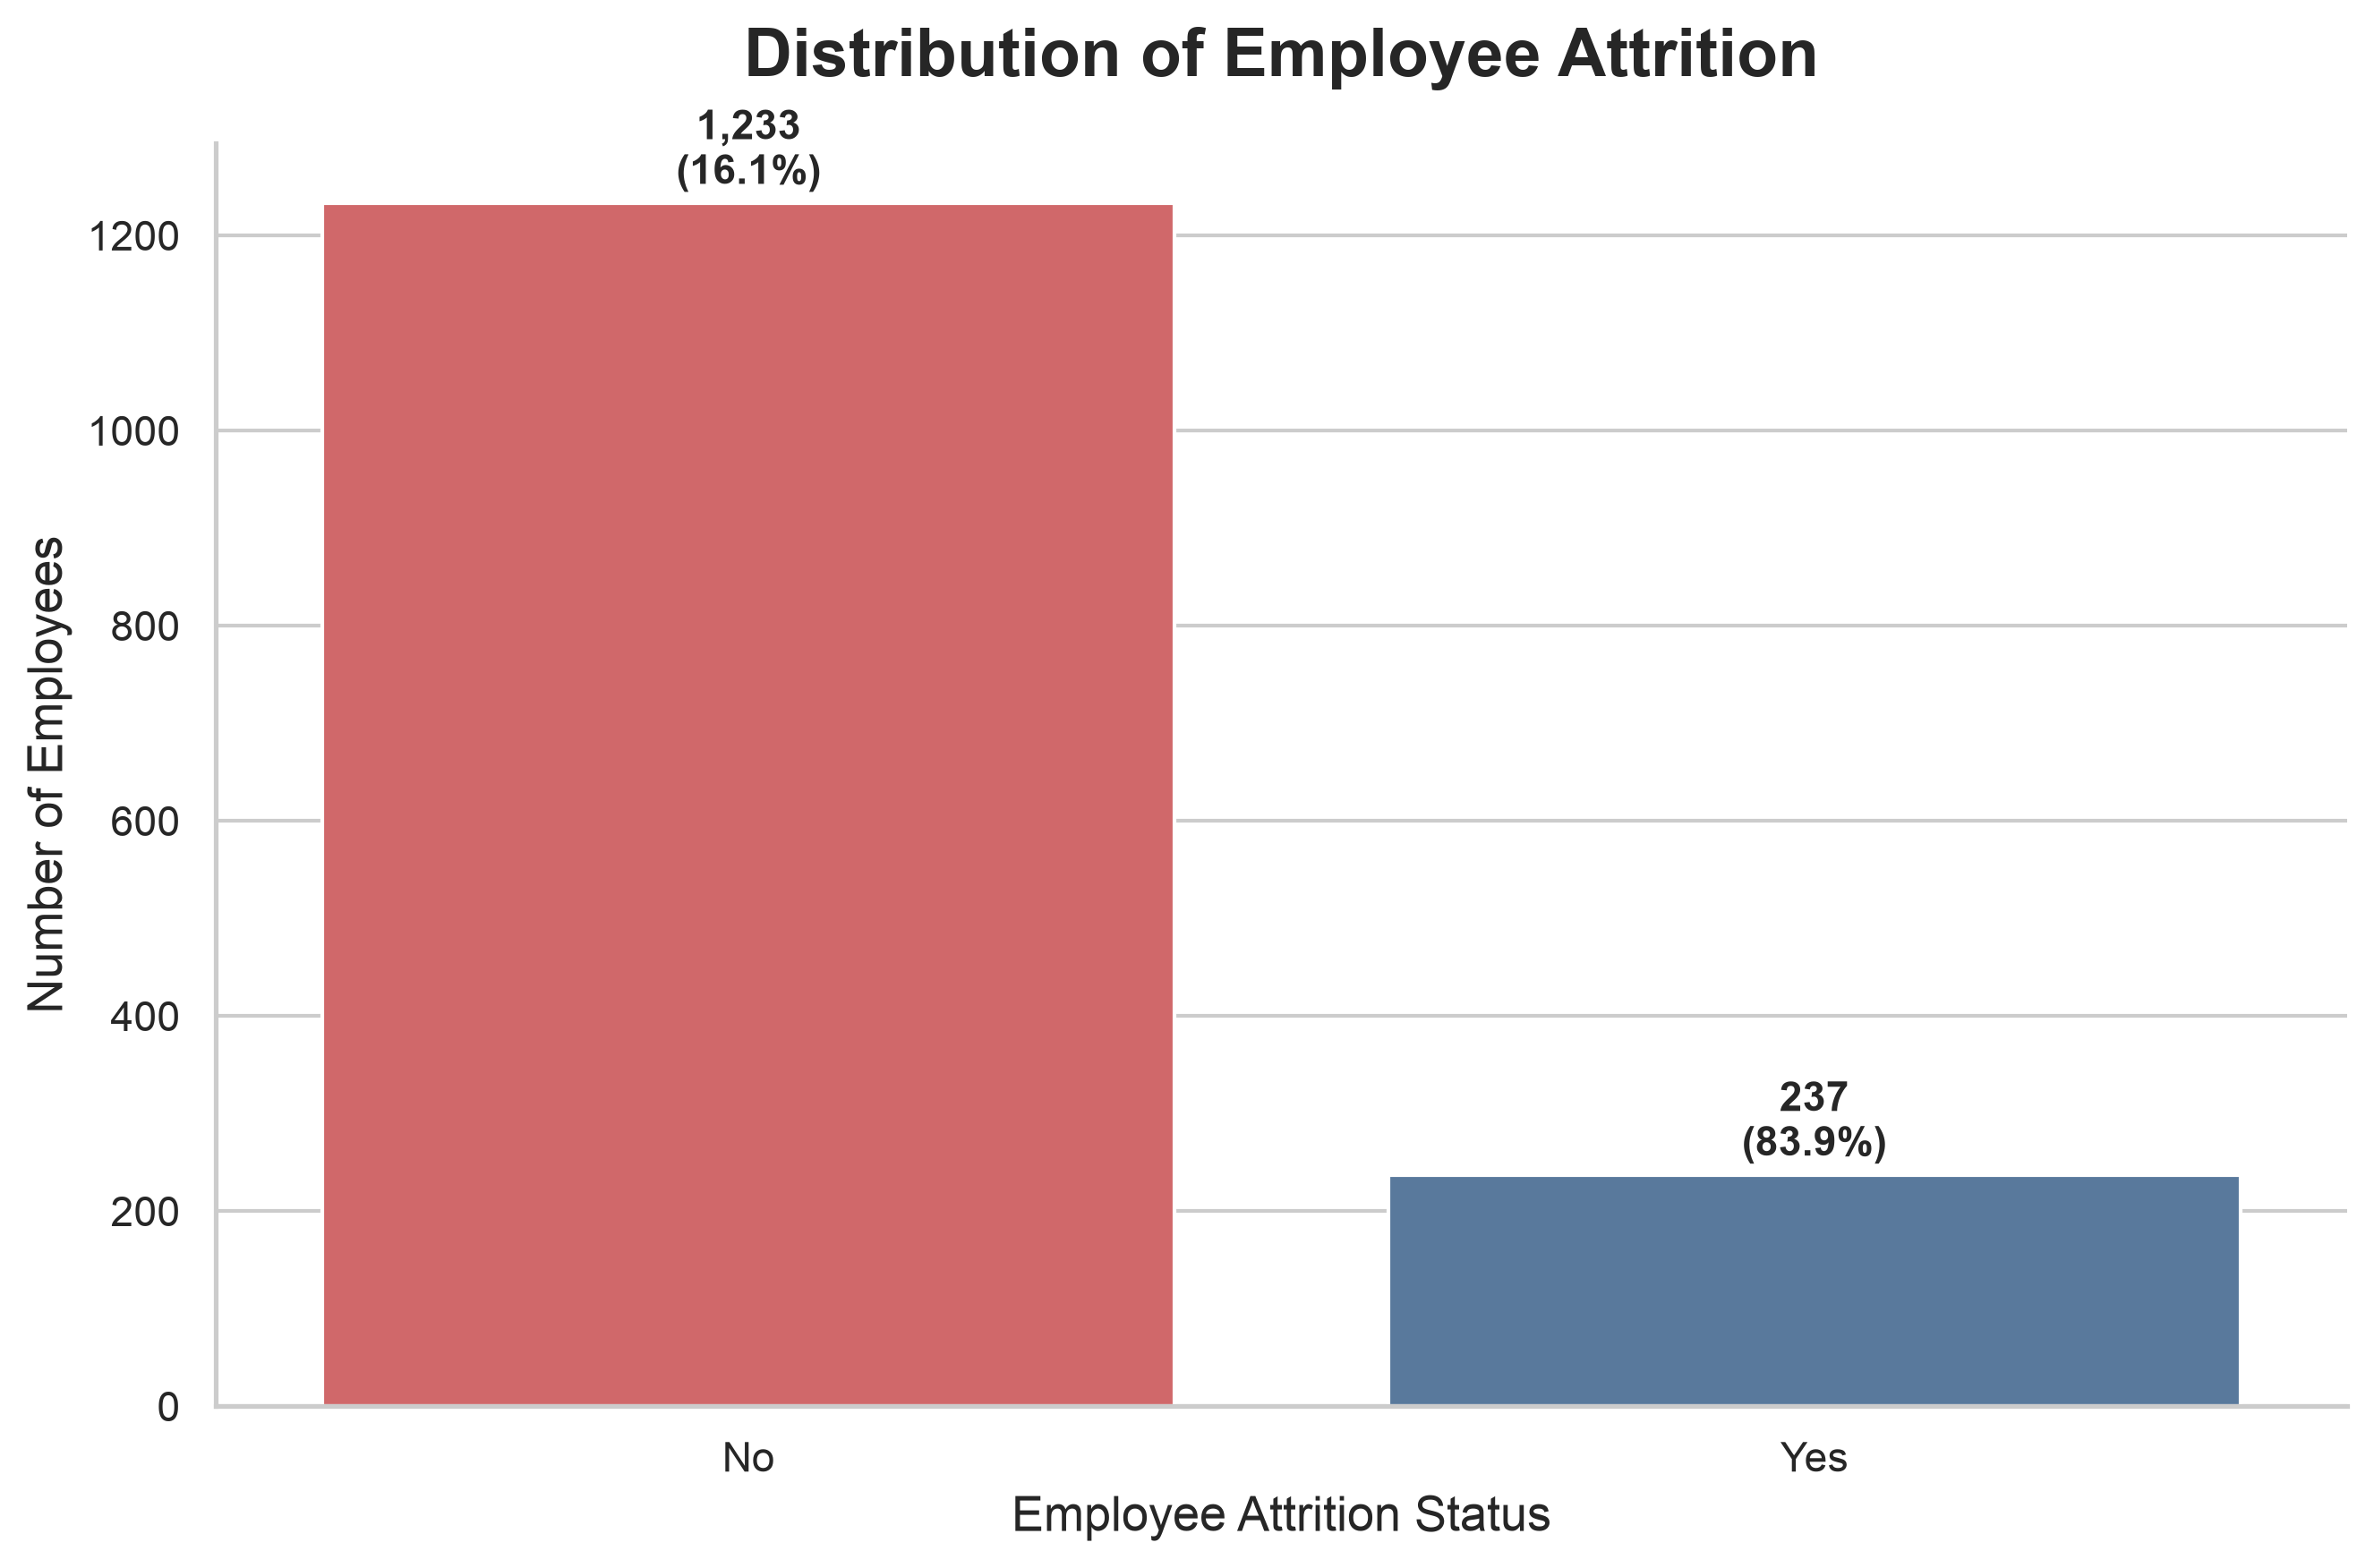

In [6]:
# Count the number of employees in each attrition category
attrition_counts = df_clean["Attrition"].value_counts()

# Calculate the percentage for each category
attrition_percent = (
    df_clean["Attrition"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

# Display the summary table
attrition_summary = pd.DataFrame({
    "Count": attrition_counts,
    "Percentage (%)": attrition_percent
})

display(attrition_summary)

# Create a professional-quality visualization
plt.figure(figsize=(9, 6), dpi=300)

ax = sns.countplot(
    data=df_clean,
    x="Attrition",
    hue="Attrition",
    order=["No", "Yes"],
    palette=["#4E79A7", "#E15759"],
    legend=False
)

# Add count and percentage above each bar
for i, bar in enumerate(ax.patches):
    height = bar.get_height()
    percent = attrition_percent.iloc[i]

    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + 20,
        f"{int(height):,}\n({percent}%)",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Improve labels and title
plt.title(
    "Distribution of Employee Attrition",
    fontsize=18,
    pad=18,
    weight="bold"
)

plt.xlabel("Employee Attrition Status", fontsize=13)
plt.ylabel("Number of Employees", fontsize=13)

# Remove unnecessary borders
sns.despine()

plt.tight_layout()

plt.show()

### Interpretation

The target variable shows that most employees remained with the company, while a much smaller portion left. Specifically, 1,233 employees, or 83.9 percent, remained employed, whereas 237 employees, or 16.1 percent, experienced attrition.

This distribution indicates that employee attrition is a relatively infrequent outcome, resulting in a moderately imbalanced classification problem. Because the majority of employees did not leave, relying on accuracy alone could produce misleading model performance. As the analysis progresses, evaluation metrics such as recall, precision, F1-score, and ROC-AUC will provide a more meaningful assessment of how well the models identify employees who are at risk of leaving.

## Section 6.2: Employee Age and Attrition

After examining the overall attrition rate, the next step is to determine whether employees who left differ from those who remained. Age is examined first because employees at different career stages may have different levels of job mobility, compensation expectations, and attachment to an organization. Comparing the age distributions of both groups helps determine whether age may be useful for explaining or predicting employee attrition.

,Employee_Count,Mean_Age,Median_Age,Minimum_Age,Maximum_Age
Attrition,,,,,
No,1233,37.6,36.0,18,60
Yes,237,33.6,32.0,18,58


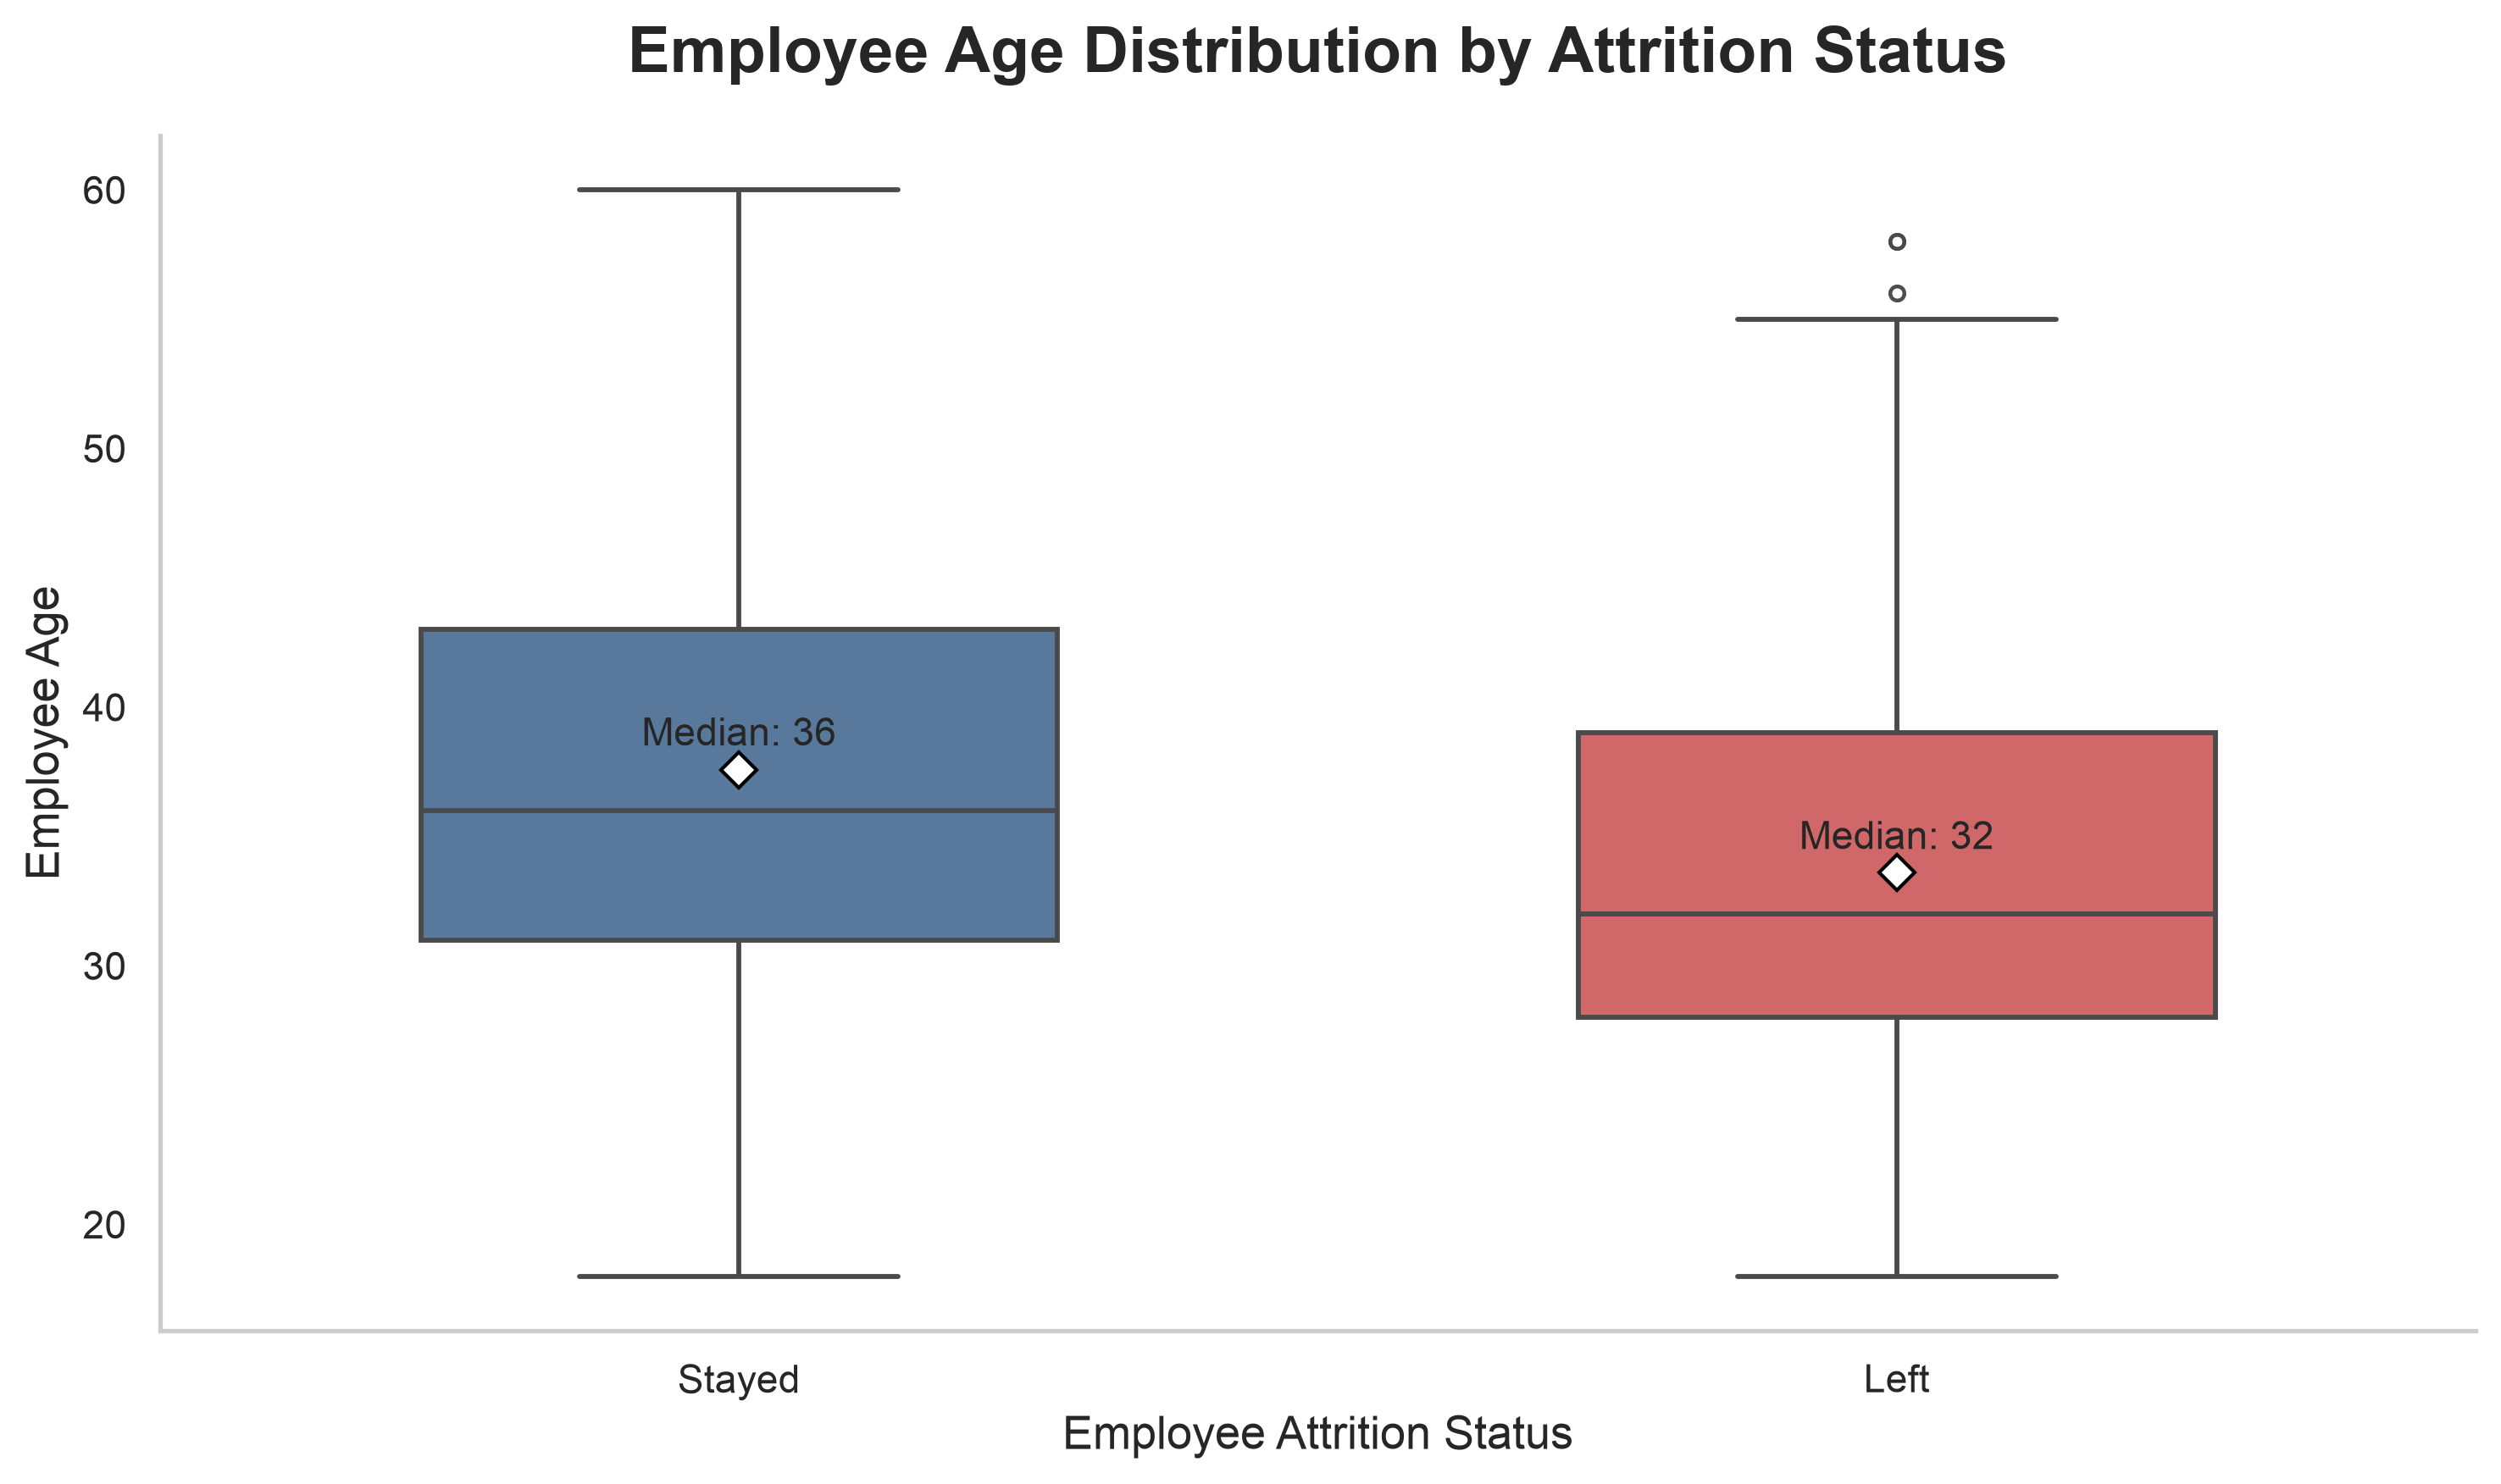

In [7]:
# Create a summary of employee age for each attrition group.
# I am comparing the average, median, range, and number of employees
# so I can better understand how age differs between employees who stayed and left.

age_summary = (
    df_clean.groupby("Attrition")["Age"]
    .agg(
        Employee_Count="count",
        Mean_Age="mean",
        Median_Age="median",
        Minimum_Age="min",
        Maximum_Age="max"
    )
    .round(1)
    .reindex(["No", "Yes"])
)

display(age_summary)

# Create a high-quality boxplot to compare employee age by attrition status.
# A boxplot is useful because it shows the median, spread, and possible outliers.

plt.figure(figsize=(10, 6), dpi=300)

ax = sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="Age",
    hue="Attrition",
    order=["No", "Yes"],
    palette={
        "No": "#4E79A7",
        "Yes": "#E15759"
    },
    width=0.55,
    linewidth=1.4,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7
    },
    flierprops={
        "marker": "o",
        "markersize": 4,
        "alpha": 0.7
    },
    legend=False
)

# Calculate the median age for each group.
median_ages = (
    df_clean.groupby("Attrition")["Age"]
    .median()
    .reindex(["No", "Yes"])
)

# Add the median value above each box so the comparison is easy to read.
for position, median_age in enumerate(median_ages):
    ax.text(
        position,
        median_age + 2.2,
        f"Median: {median_age:.0f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

# Add a clear title and axis labels.
plt.title(
    "Employee Age Distribution by Attrition Status",
    fontsize=18,
    pad=18,
    weight="bold"
)

plt.xlabel("Employee Attrition Status", fontsize=13)
plt.ylabel("Employee Age", fontsize=13)

# Replace the original category labels with more natural wording.
plt.xticks(
    ticks=[0, 1],
    labels=["Stayed", "Left"],
    fontsize=11
)

plt.yticks(fontsize=11)

# Remove unnecessary gridlines and borders for a cleaner result.
ax.grid(False)
sns.despine()

plt.tight_layout()
plt.show()

### Interpretation

Employees who left the company tended to be younger than those who remained. The average age of employees who stayed was 37.6 years, compared to 33.6 years for employees who left. A similar pattern is observed in the median ages, where employees who remained had a median age of 36 years, while employees who left had a median age of 32 years.

Although the distributions overlap, the overall shift toward younger ages suggests that age may be associated with employee attrition. However, the overlap also indicates that age alone is unlikely to explain why employees leave and should be evaluated alongside other workplace and demographic factors during the remainder of the analysis.

## Section 6.3: Overtime and Employee Attrition

After examining employee age, the next step is to investigate whether working overtime is associated with employee attrition. Overtime is an important workplace characteristic because excessive workloads and long working hours may contribute to employee stress, reduced work-life balance, and an increased likelihood of leaving the organization. Comparing attrition rates between employees who work overtime and those who do not helps determine whether overtime may be an important predictor of employee attrition.

Attrition,No,Yes
OverTime,,
No,89.6,10.4
Yes,69.5,30.5


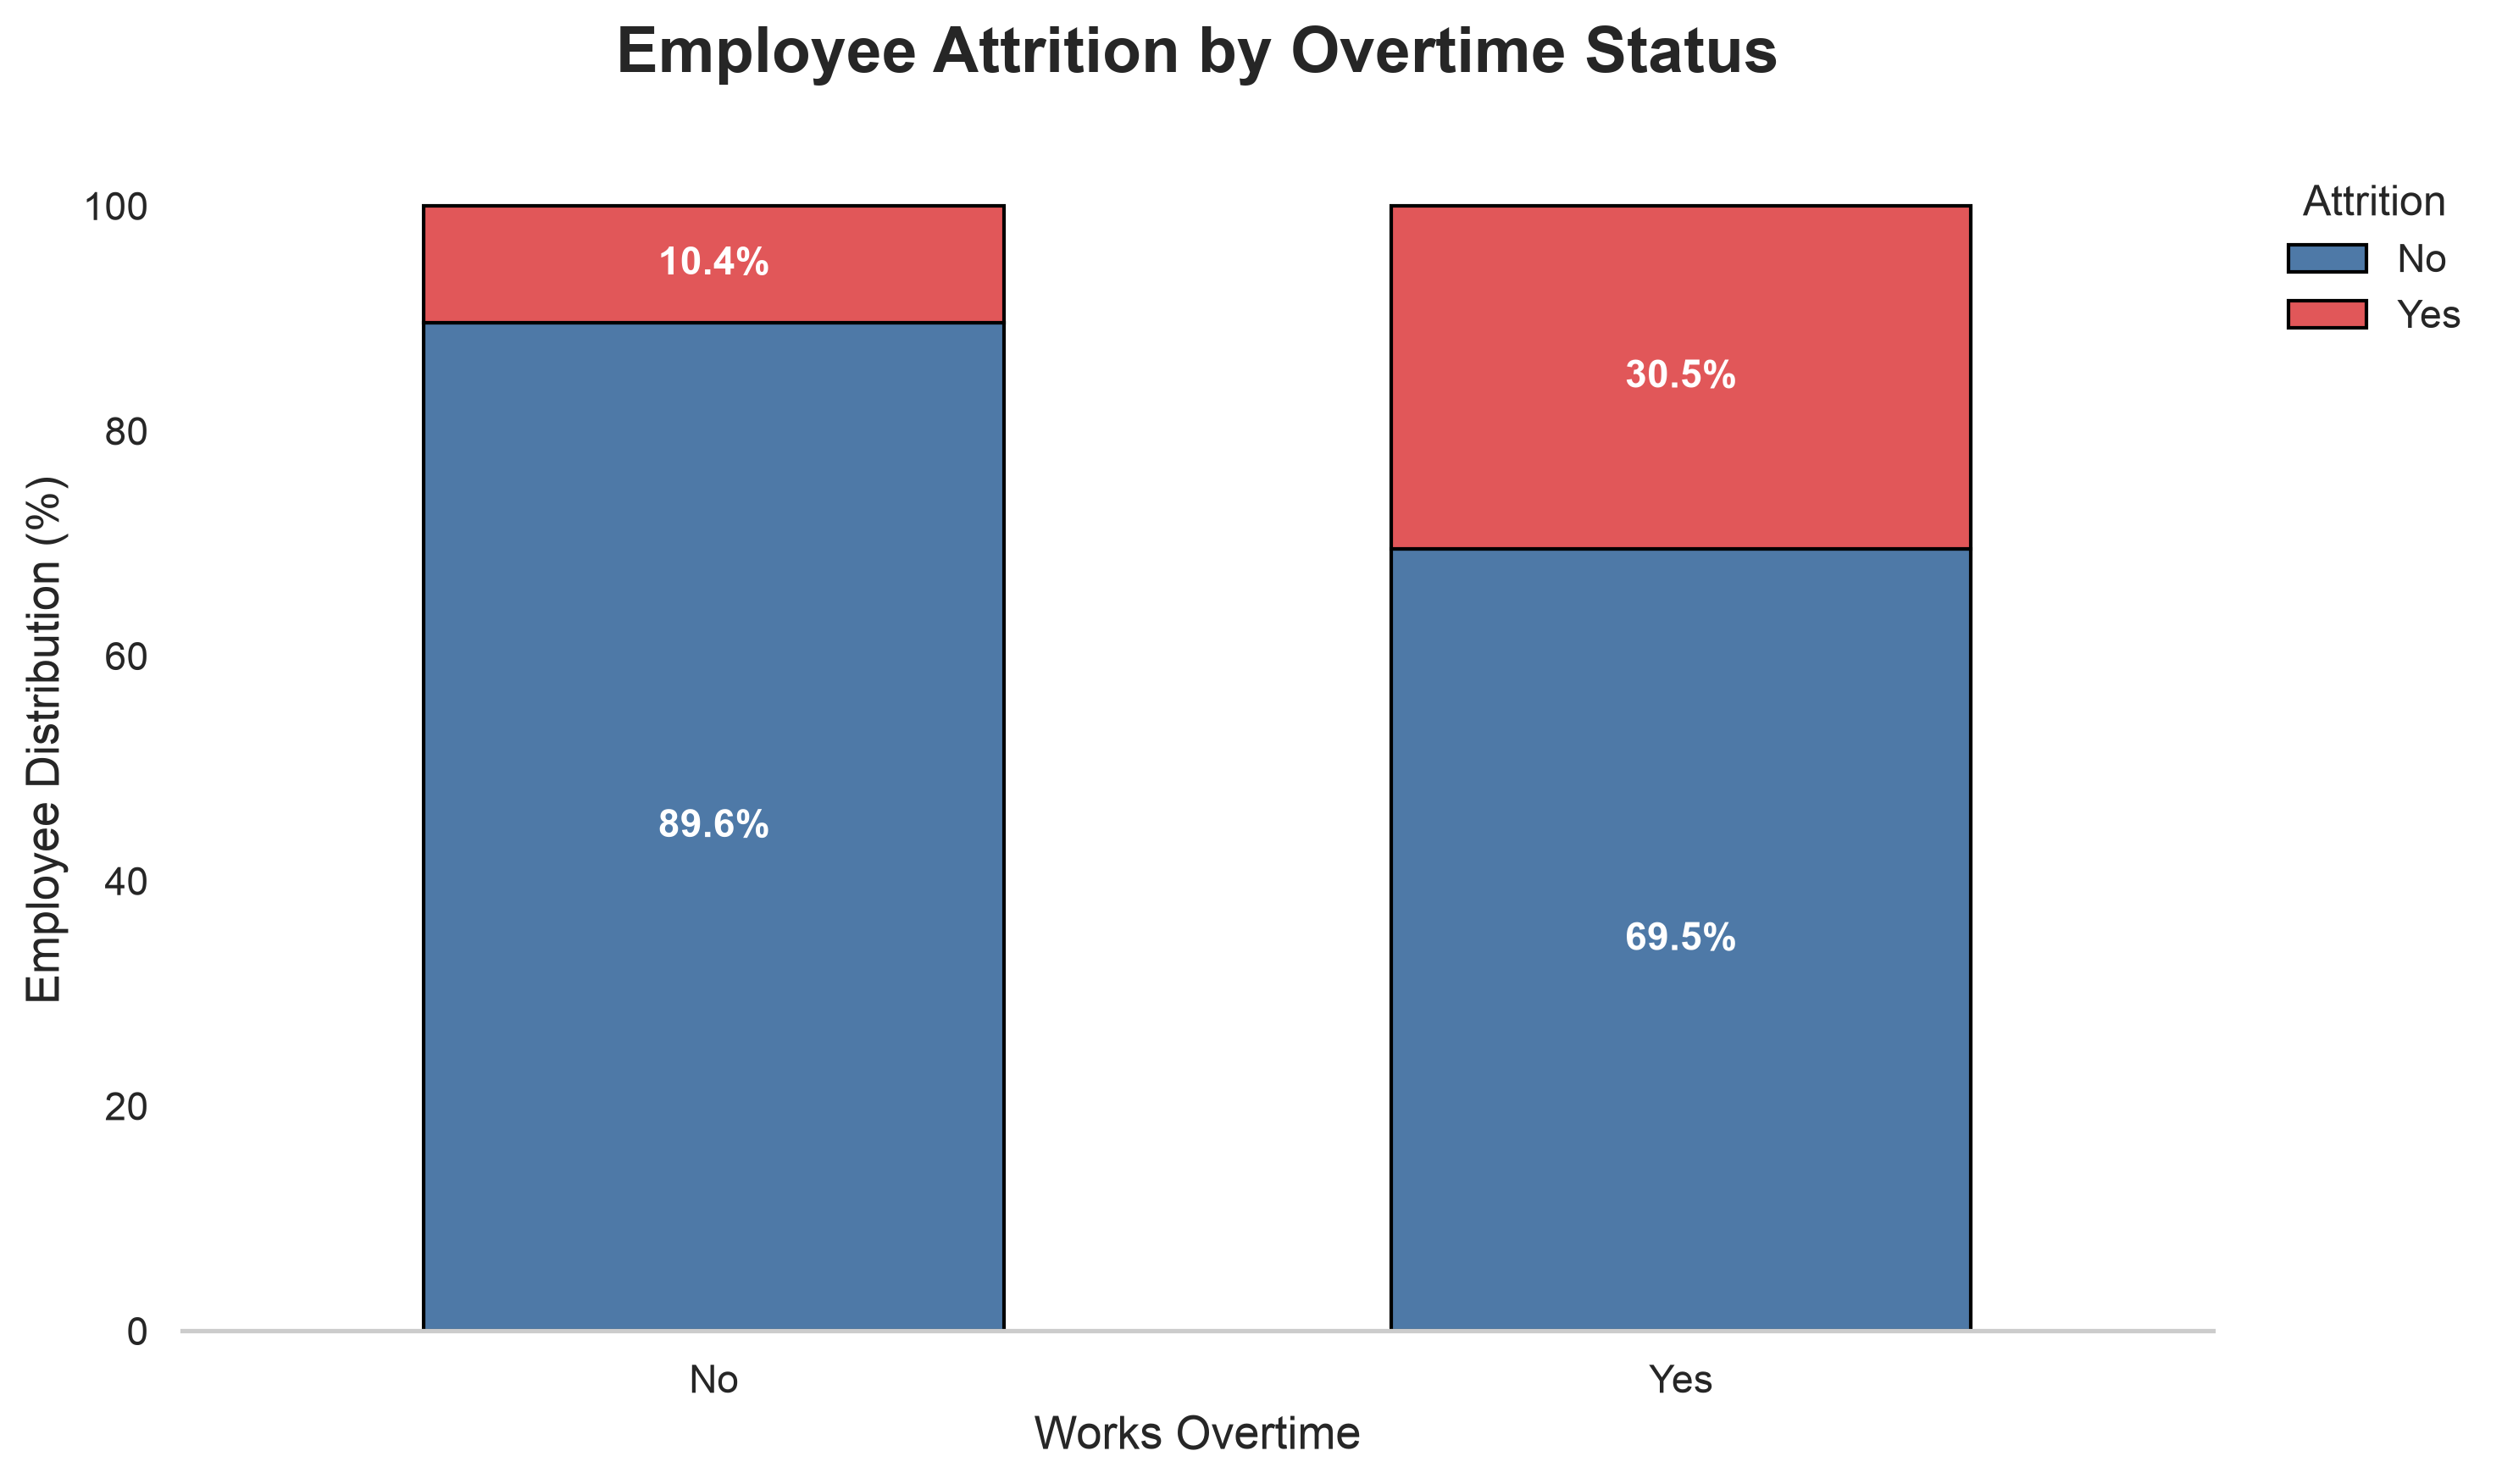

In [8]:
# Compare employee attrition based on overtime status.
# I want to see whether employees who work overtime
# are more likely to leave the company.

# Calculate the percentage of employees within each overtime group.
overtime_percent = (
    pd.crosstab(
        df_clean["OverTime"],
        df_clean["Attrition"],
        normalize="index"
    ) * 100
).round(1)

display(overtime_percent)

# Create a professional-quality normalized stacked bar chart.
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

colors = ["#4E79A7", "#E15759"]

overtime_percent.loc[["No", "Yes"]].plot(
    kind="bar",
    stacked=True,
    color=colors,
    edgecolor="black",
    width=0.6,
    ax=ax
)

# Add percentage labels inside each section of the bars.
for container in ax.containers:
    labels = [
        f"{value:.1f}%" if value >= 5 else ""
        for value in container.datavalues
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=11,
        color="white",
        fontweight="bold"
    )

# Improve the overall appearance of the visualization.
plt.title(
    "Employee Attrition by Overtime Status",
    fontsize=18,
    fontweight="bold",
    pad=22
)

plt.xlabel("Works Overtime", fontsize=13)
plt.ylabel("Employee Distribution (%)", fontsize=13)

plt.xticks(rotation=0, fontsize=11)
plt.yticks(fontsize=11)

plt.legend(
    title="Attrition",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

# Remove unnecessary borders and gridlines.
ax.grid(False)
sns.despine(left=True)

plt.tight_layout()
plt.show()

### Interpretation

Overtime appears to have a strong relationship with employee attrition. Among employees who did not work overtime, only 10.4 percent left the company. In contrast, 30.5 percent of employees who worked overtime experienced attrition.

This difference suggests that employees working overtime are substantially more likely to leave the organization than employees who do not work overtime. While this relationship does not imply that overtime directly causes attrition, it indicates that overtime may be an important predictor of employee turnover and should be included in the predictive models developed later in this project.

## Section 6.4: Job Satisfaction and Employee Attrition

Job satisfaction is often considered one of the most important factors influencing employee retention. Employees who are dissatisfied with their work may be more likely to seek opportunities elsewhere, while employees who are satisfied may be more likely to remain with the organization. This section examines the relationship between job satisfaction and employee attrition to determine whether lower satisfaction levels are associated with higher employee turnover.

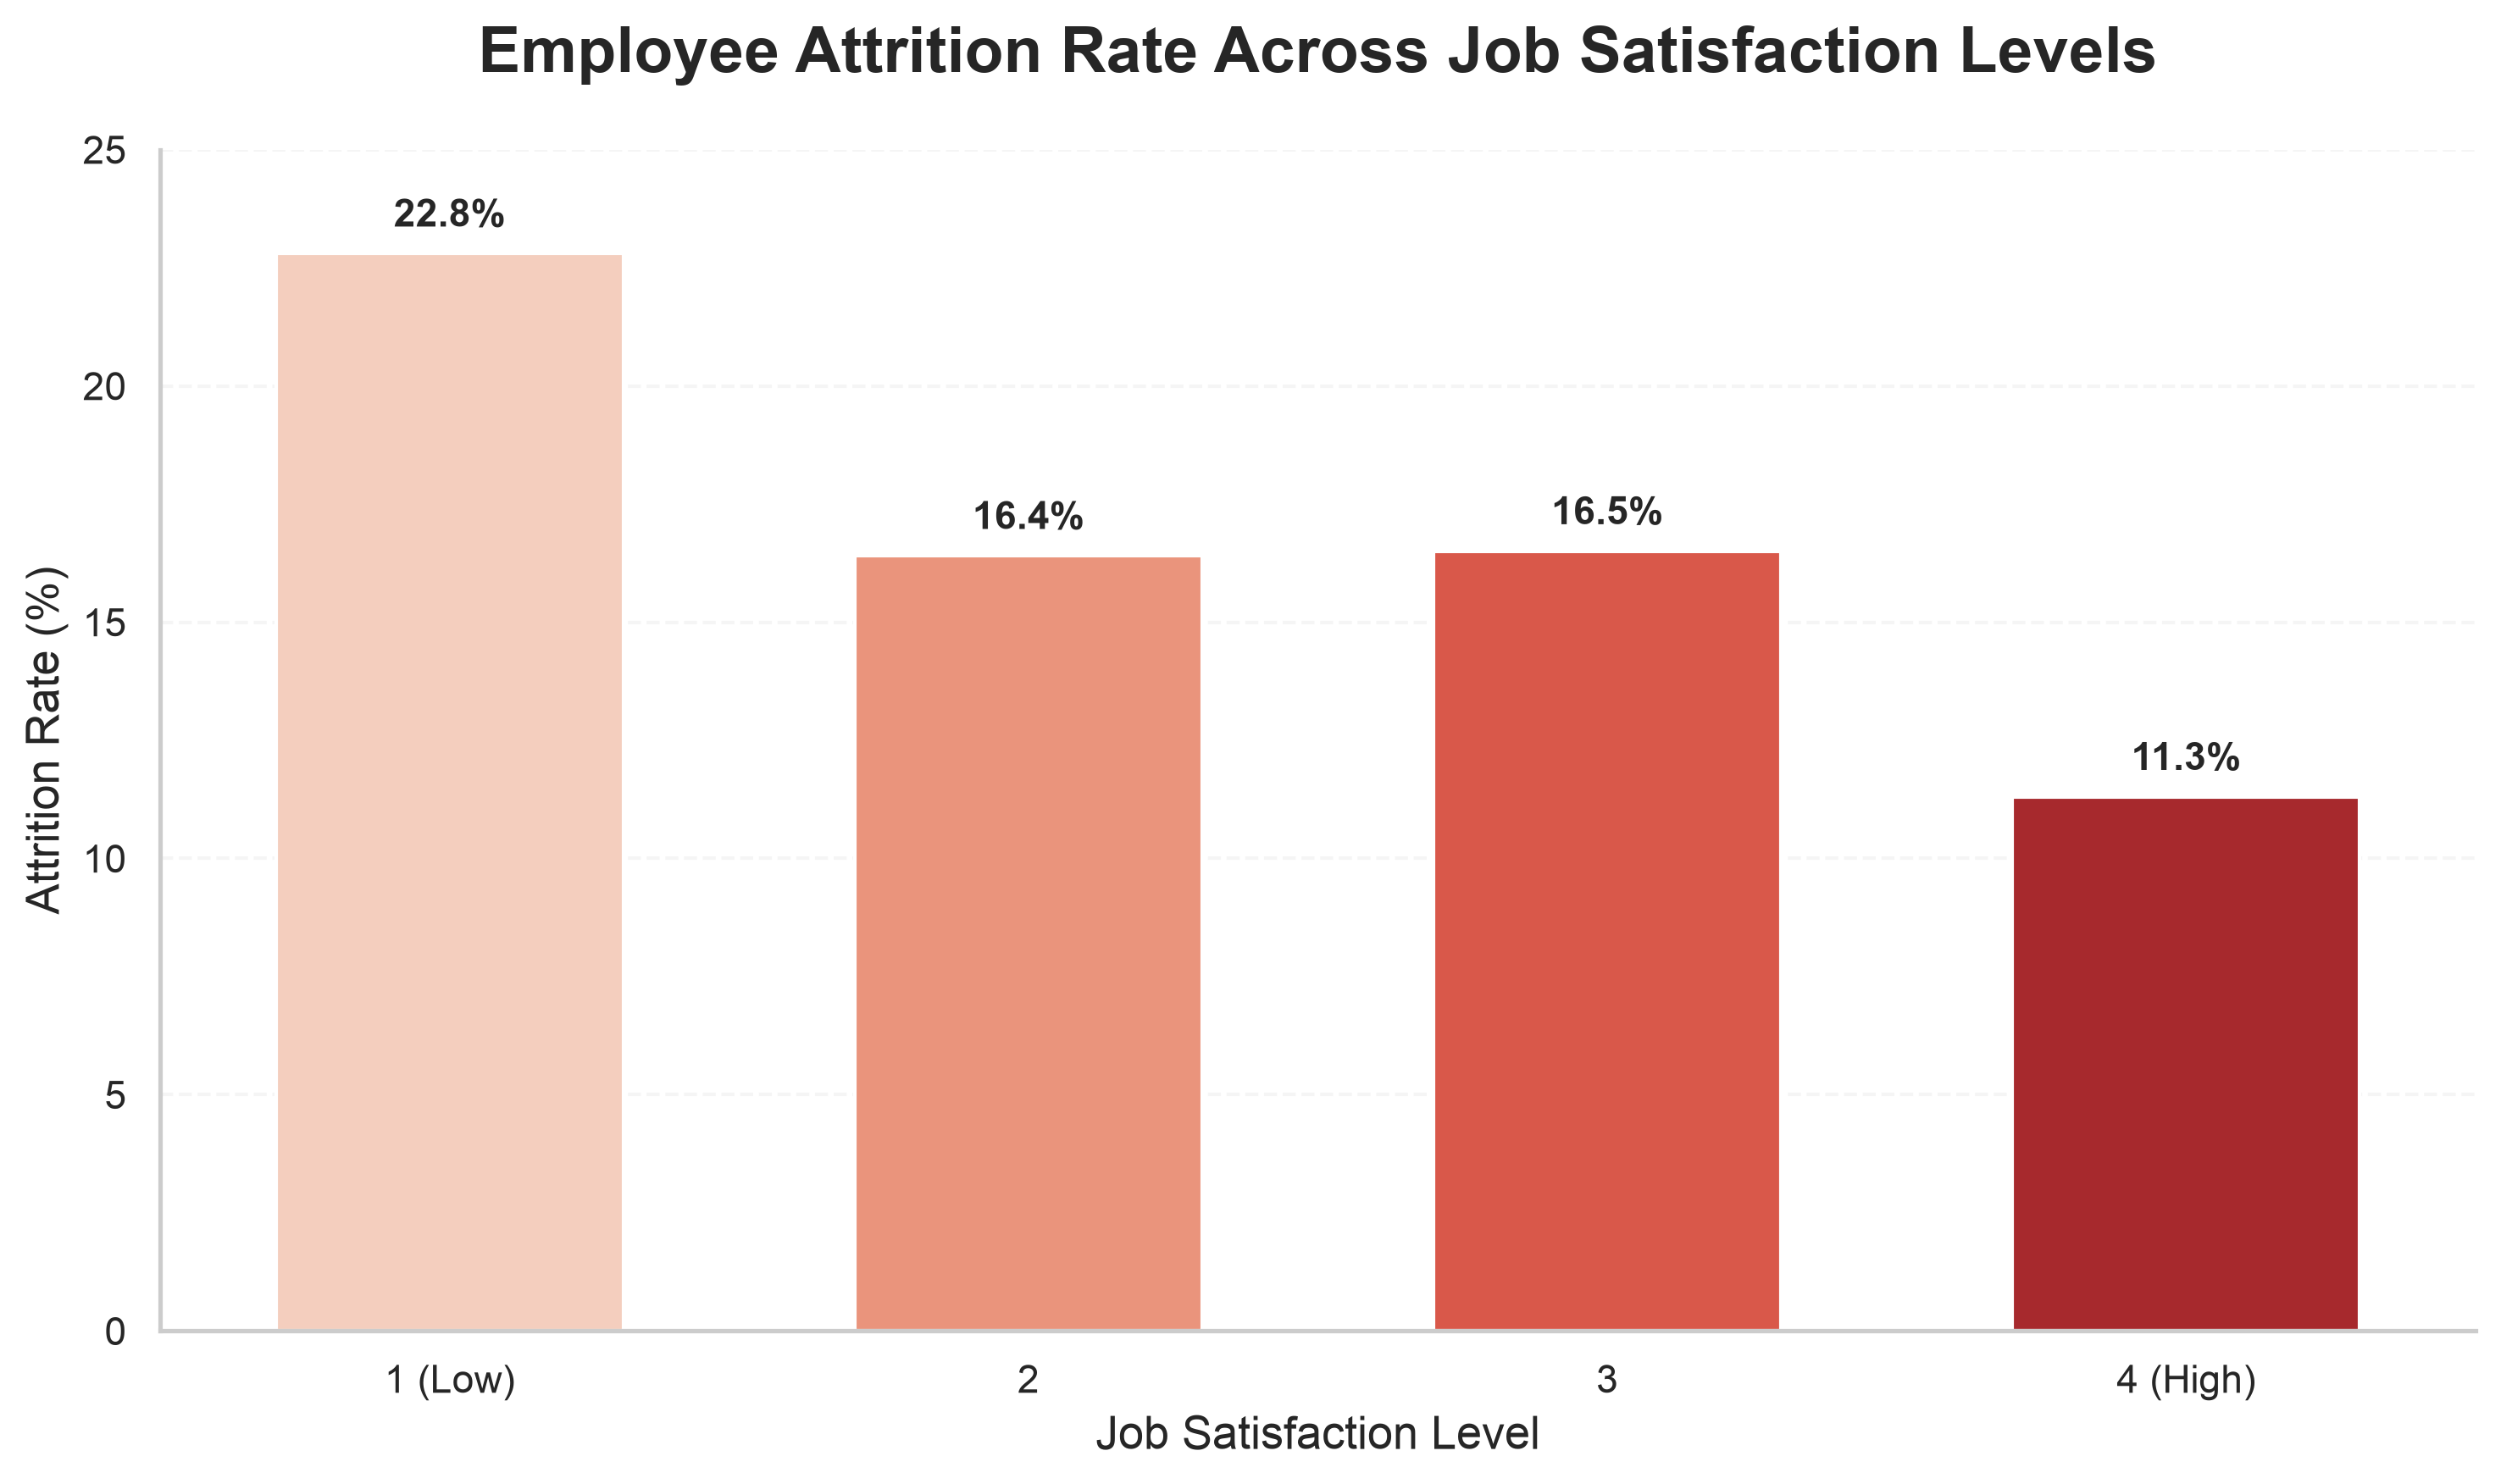

In [9]:
# Compare the attrition rate across job satisfaction levels.
# I want to see whether employees with lower job satisfaction
# are more likely to leave the company.

# Calculate the attrition percentage for each job satisfaction level.
job_attrition = (
    pd.crosstab(
        df_clean["JobSatisfaction"],
        df_clean["Attrition"],
        normalize="index"
    )["Yes"]
    .mul(100)
    .round(1)
)

# Rename the satisfaction levels so they are easier to understand.
job_attrition.index = [
    "1 (Low)",
    "2",
    "3",
    "4 (High)"
]

# Create a professional-quality visualization.
plt.figure(figsize=(10, 6), dpi=300)

palette = sns.color_palette("Reds", 4)

ax = sns.barplot(
    x=job_attrition.index,
    hue=job_attrition.index,
    y=job_attrition.values,
    palette=palette,
    legend=False,
    width=0.6
)

# Add the attrition percentage above each bar.
for bar in ax.patches:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.4,
        f"{height:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Employee Attrition Rate Across Job Satisfaction Levels",
    fontsize=18,
    fontweight="bold",
    pad=22
)

plt.xlabel("Job Satisfaction Level", fontsize=13)
plt.ylabel("Attrition Rate (%)", fontsize=13)

plt.ylim(0, 25)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

ax.grid(axis="y", linestyle="--", alpha=0.18)
sns.despine()

plt.tight_layout()

plt.show()

### Interpretation

Employees with the lowest job satisfaction experienced the highest attrition rate, with 22.8 percent leaving the organization. Employees reporting moderate job satisfaction had similar attrition rates of approximately 16 percent, while employees with the highest level of job satisfaction experienced the lowest attrition rate at 11.3 percent.

These results indicate that job satisfaction is associated with employee retention, although the relationship is not perfectly linear across all satisfaction levels. Employees with the lowest satisfaction appear to be at the greatest risk of leaving, while employees with the highest satisfaction are the most likely to remain with the organization. This finding suggests that job satisfaction may be an important predictor of employee attrition and should be included in the predictive models developed later in this project.

## Section 6.5: Monthly Income and Employee Attrition

Compensation is an important factor that may influence an employee's decision to remain with an organization. Employees who feel they are not fairly compensated may be more likely to seek employment elsewhere. This section compares the monthly income distributions of employees who remained with the organization and those who left to determine whether compensation may be associated with employee attrition.

,Employee_Count,Mean_Income,Median_Income,Minimum_Income,Maximum_Income
Attrition,,,,,
No,1233,6833,5204,1051,19999
Yes,237,4787,3202,1009,19859


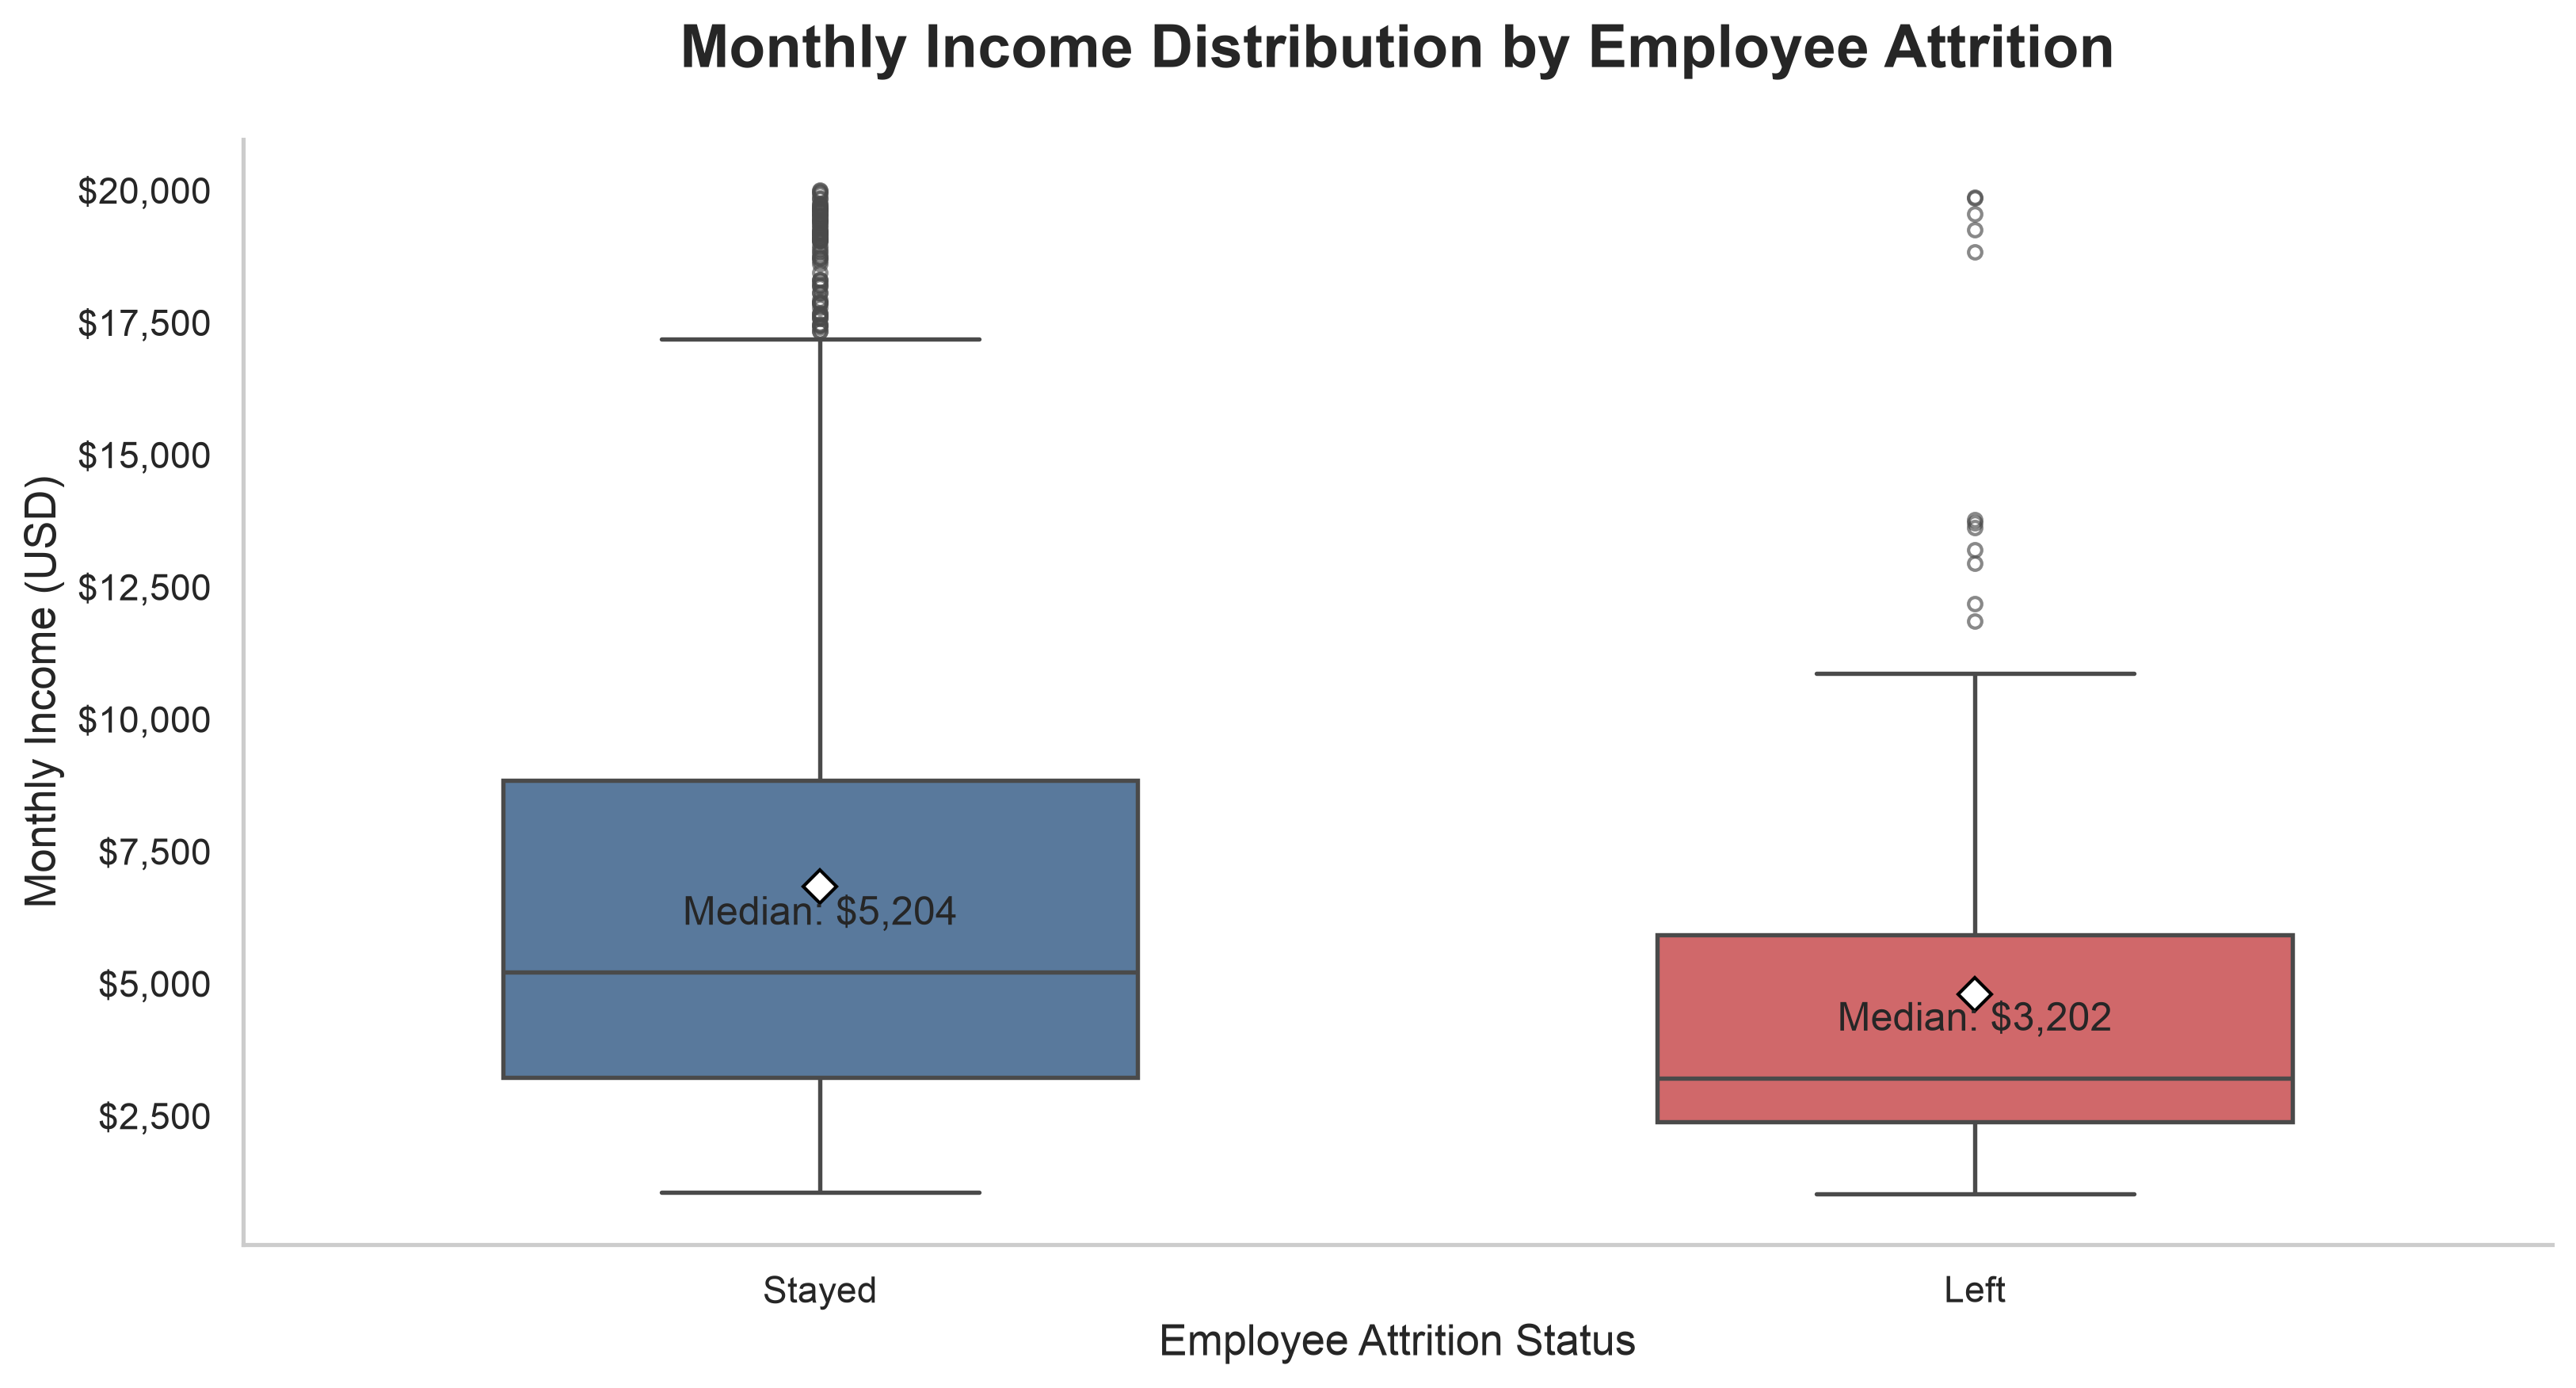

In [10]:
# Compare monthly income between employees who stayed
# and employees who left the company.
# I want to see if employees who leave generally earn less.

# Display summary statistics for each attrition group.
income_summary = (
    df_clean.groupby("Attrition")["MonthlyIncome"]
    .agg(
        Employee_Count="count",
        Mean_Income="mean",
        Median_Income="median",
        Minimum_Income="min",
        Maximum_Income="max"
    )
    .round(0)
    .astype(int)
    .reindex(["No", "Yes"])
)

display(income_summary)

# Create a professional-quality boxplot.
plt.figure(figsize=(11, 6), dpi=300)

ax = sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="MonthlyIncome",
    hue="Attrition",
    order=["No", "Yes"],
    palette={
        "No": "#4E79A7",
        "Yes": "#E15759"
    },
    width=0.55,
    linewidth=1.3,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7
    },
    flierprops={
        "marker": "o",
        "markersize": 4,
        "alpha": 0.65
    },
    legend=False
)

# Calculate the median monthly income for each group.
median_income = (
    df_clean.groupby("Attrition")["MonthlyIncome"]
    .median()
    .reindex(["No", "Yes"])
)

# Display the median above each box.
for position, median in enumerate(median_income):

    ax.text(
        position,
        median + 900,
        f"Median: ${median:,.0f}",
        ha="center",
        fontsize=12
    )

plt.title(
    "Monthly Income Distribution by Employee Attrition",
    fontsize=18,
    fontweight="bold",
    pad=22
)

plt.xlabel("Employee Attrition Status", fontsize=13)
plt.ylabel("Monthly Income (USD)", fontsize=13)

plt.xticks(
    ticks=[0, 1],
    labels=["Stayed", "Left"],
    fontsize=11
)

plt.yticks(fontsize=11)

# Format the y-axis as currency.
from matplotlib.ticker import StrMethodFormatter

ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

# Keep the full income range visible.
ax.grid(False)
sns.despine()

plt.tight_layout()

plt.show()

### Interpretation

Employees who remained with the organization generally earned higher monthly incomes than employees who left. The median monthly income for employees who stayed was $5,204, compared to $3,202 for employees who experienced attrition. A similar pattern was observed for the average monthly income, with employees who stayed earning approximately $2,000 more per month than those who left.

Although the income distributions overlap, the lower median and average incomes among employees who left suggest that compensation may be associated with employee attrition. Monthly income appears to be a meaningful predictor of employee attrition and should be evaluated alongside other demographic and workplace characteristics when developing predictive models.

## Section 6.6: Work-Life Balance and Employee Attrition

Work-life balance reflects how employees perceive the balance between their professional responsibilities and personal lives. Maintaining a healthy work-life balance is often associated with greater job satisfaction, improved well-being, and increased employee retention. This section examines whether employees reporting lower work-life balance experience higher rates of attrition.

,Attrition Rate (%)
1 (Poor),31.2
2,16.9
3,14.2
4 (Best),17.6


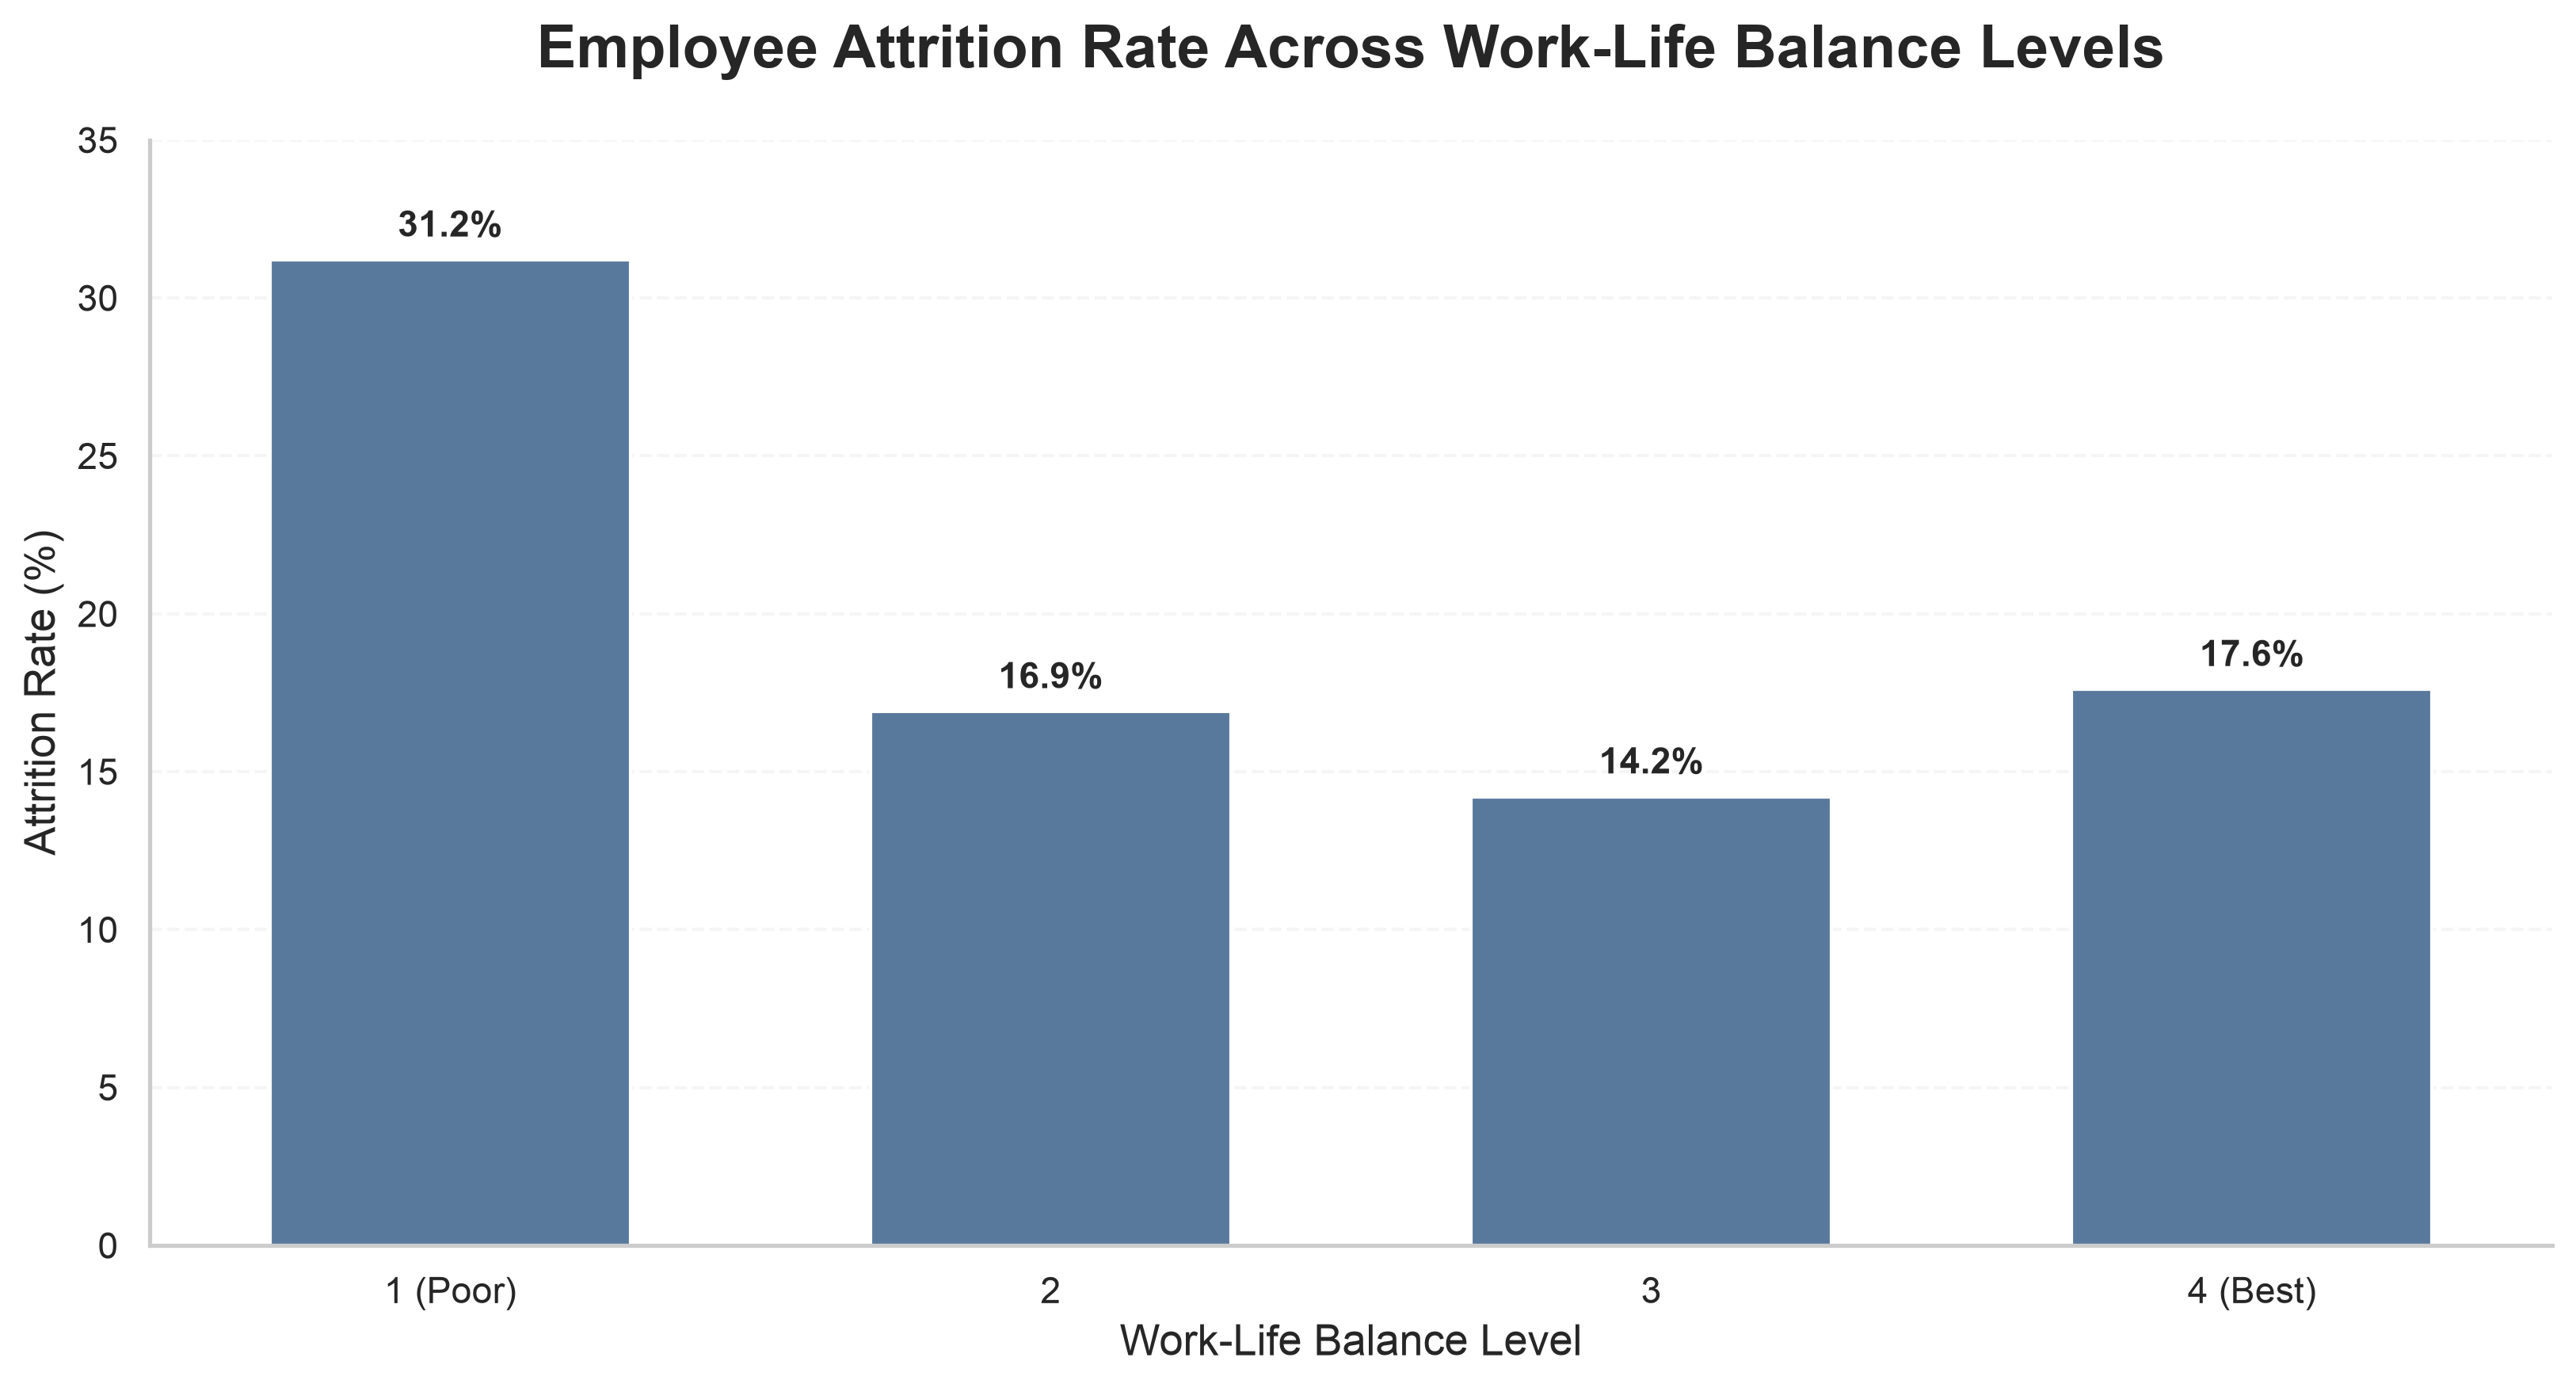

In [11]:
# Compare the attrition rate across work-life balance levels.
# I want to see whether employees reporting poorer work-life balance
# are more likely to leave the company.

# Calculate the attrition percentage for each work-life balance level.
worklife_attrition = (
    pd.crosstab(
        df_clean["WorkLifeBalance"],
        df_clean["Attrition"],
        normalize="index"
    )["Yes"]
    .mul(100)
    .round(1)
)

# Rename the work-life balance levels.
worklife_attrition.index = [
    "1 (Poor)",
    "2",
    "3",
    "4 (Best)"
]

display(worklife_attrition.to_frame(name="Attrition Rate (%)"))

# Create the visualization.
plt.figure(figsize=(11, 6), dpi=300)

ax = sns.barplot(
    x=worklife_attrition.index,
    y=worklife_attrition.values,
    color="#4E79A7",
    width=0.6
)

# Add the attrition percentage above each bar.
for bar in ax.patches:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.5,
        f"{height:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Employee Attrition Rate Across Work-Life Balance Levels",
    fontsize=18,
    fontweight="bold",
    pad=22
)

plt.xlabel("Work-Life Balance Level", fontsize=13)
plt.ylabel("Attrition Rate (%)", fontsize=13)

plt.ylim(0, 35)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

ax.grid(axis="y", linestyle="--", alpha=0.18)
sns.despine()

plt.tight_layout()
plt.show()

### Interpretation

Employees reporting the poorest work-life balance experienced the highest attrition rate at 31.2 percent, which was substantially higher than the other work-life balance groups. Employees reporting work-life balance levels of 2 and 3 had considerably lower attrition rates of 16.9 percent and 14.2 percent, respectively. Employees reporting the highest work-life balance experienced an attrition rate of 17.6 percent.

These results suggest that poor work-life balance may be associated with employee attrition, particularly for employees reporting the lowest level of work-life balance. However, the relationship is not perfectly linear because employees reporting the highest work-life balance did not have the lowest attrition rate. This indicates that work-life balance should be evaluated alongside other workplace and demographic characteristics when developing predictive models.

## Section 6.7: Business Travel and Employee Attrition

Business travel can influence employee satisfaction, stress levels, and work-life balance. Employees who travel frequently may experience greater fatigue and spend more time away from family, while employees who rarely travel may have different workplace experiences. This section examines whether the frequency of business travel is associated with employee attrition.

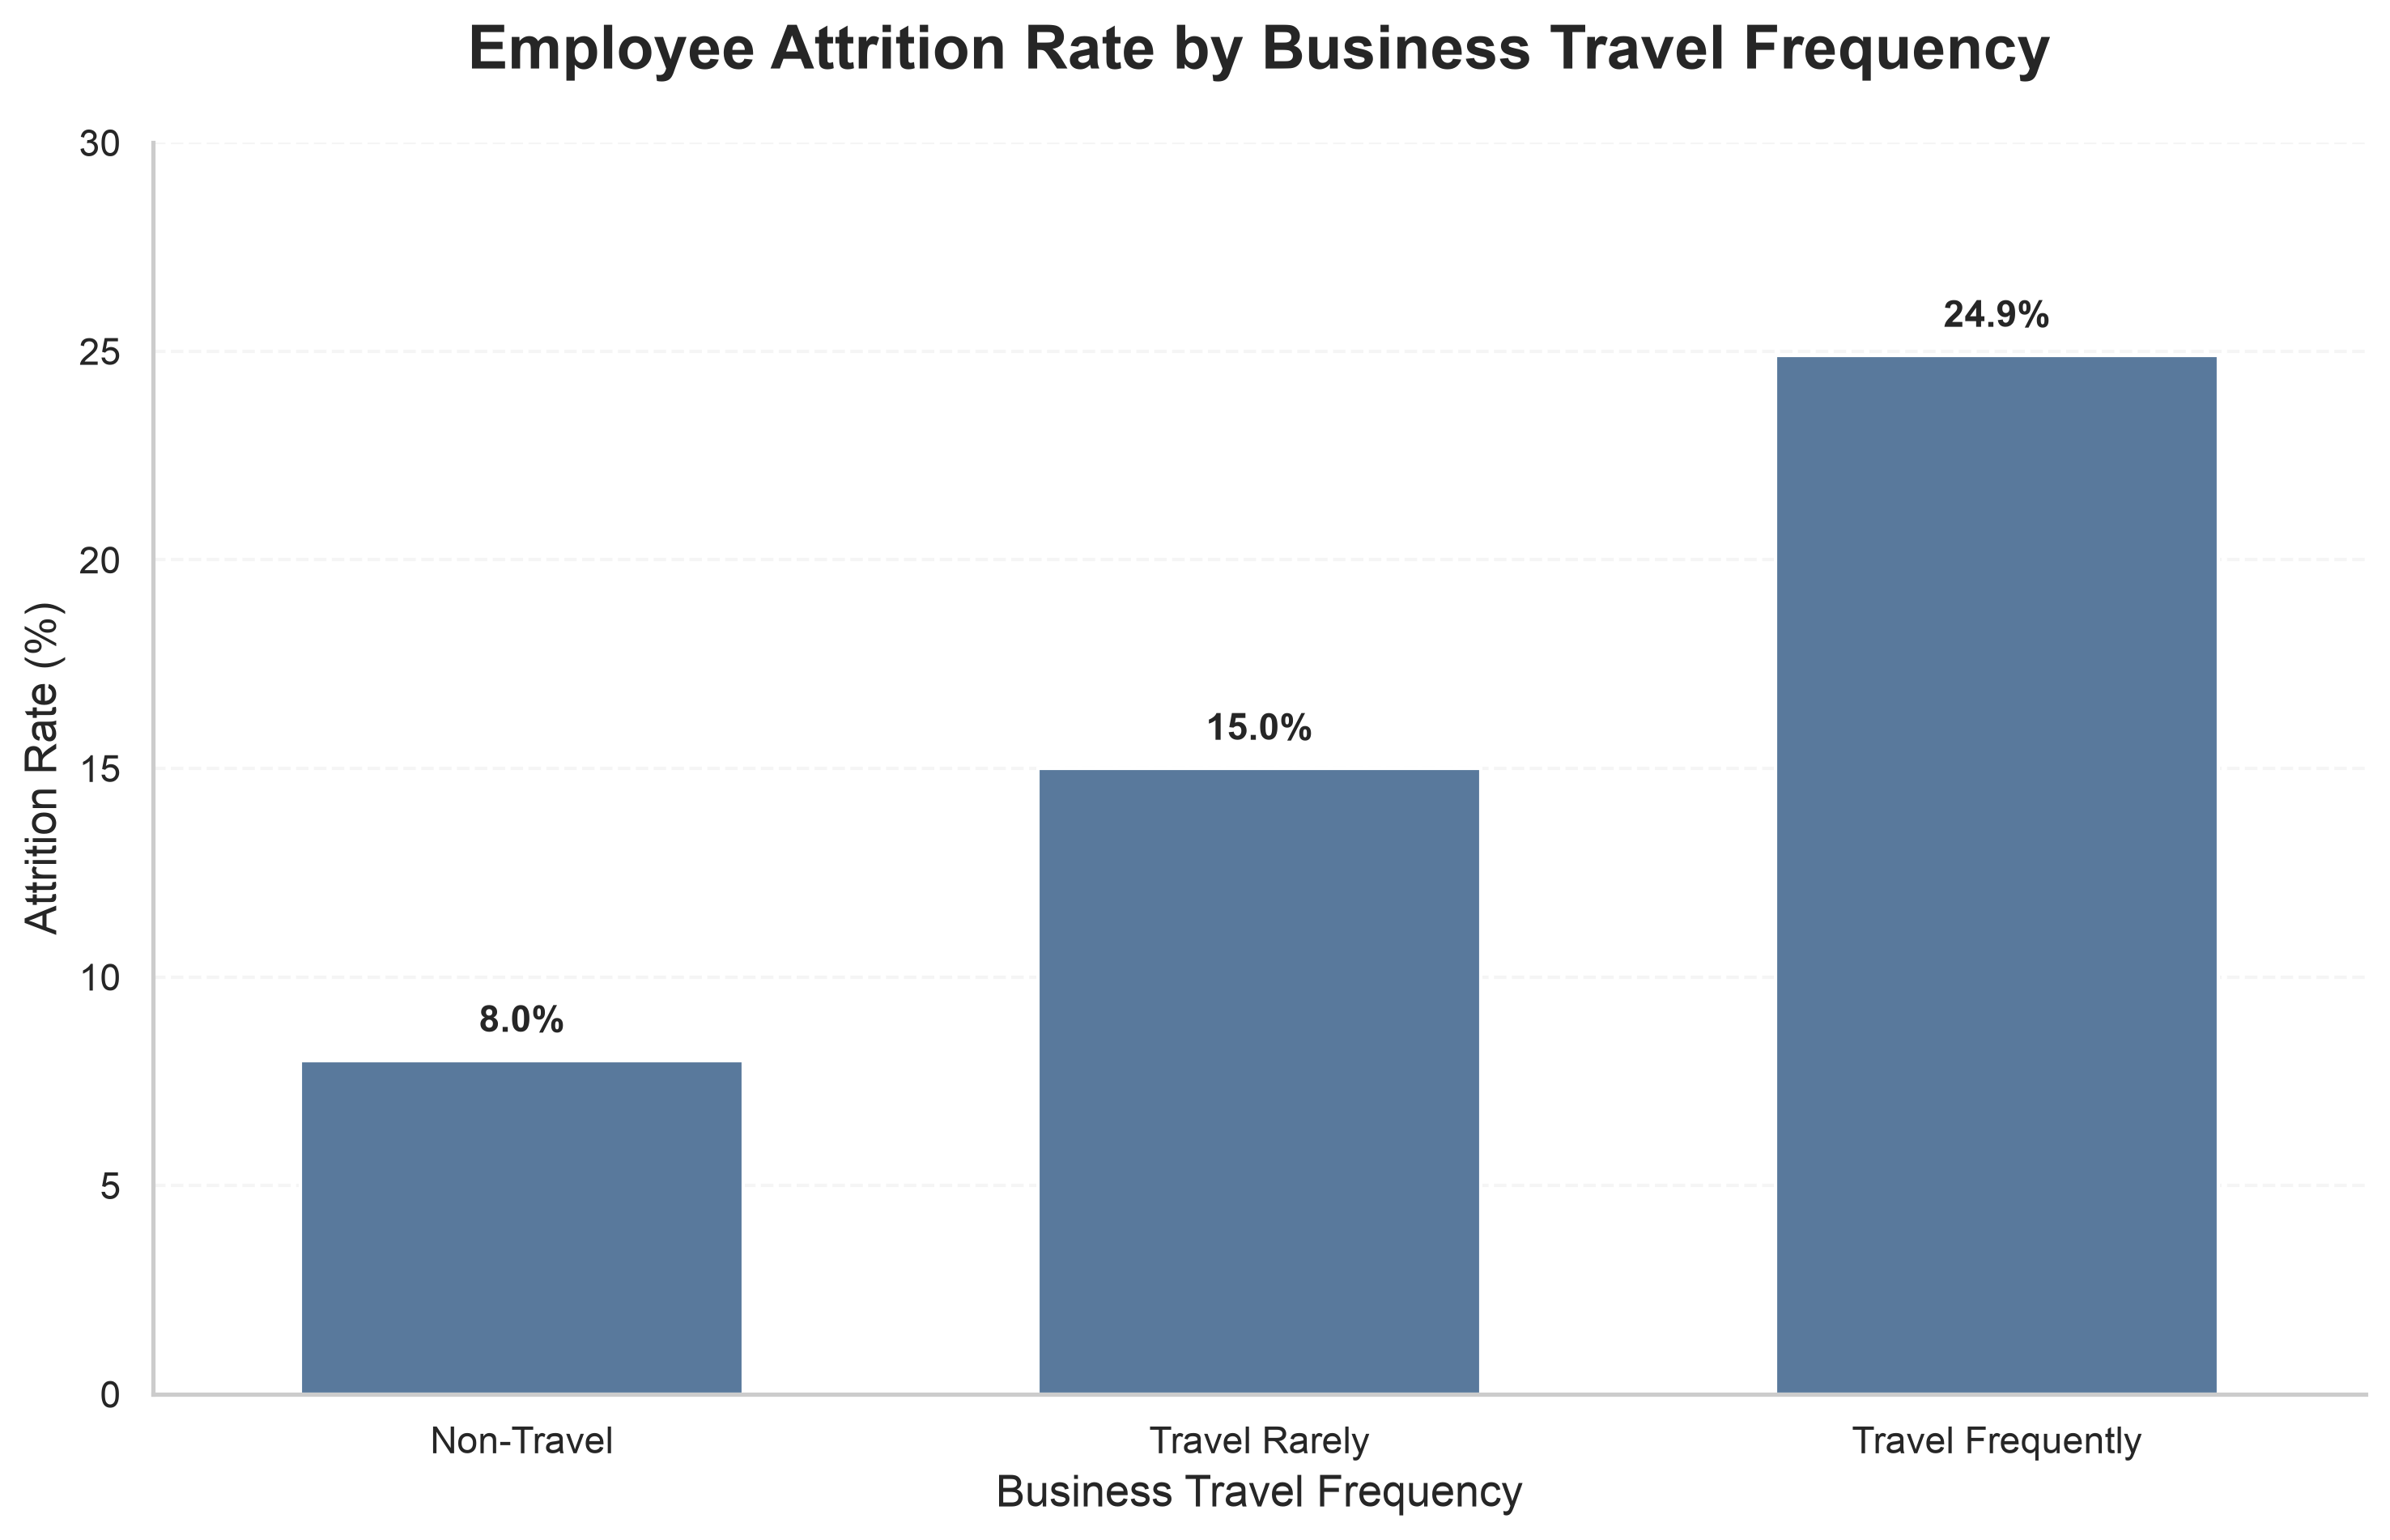

In [12]:
# Compare attrition rates across business travel categories.
# I want to determine whether employees who travel more frequently
# experience higher rates of attrition.

# Calculate the attrition rate for each travel category.
travel_attrition = (
    pd.crosstab(
        df_clean["BusinessTravel"],
        df_clean["Attrition"],
        normalize="index"
    )["Yes"]
    .mul(100)
    .round(1)
)

# Arrange the travel categories from least to most travel.
travel_order = [
    "Non-Travel",
    "Travel_Rarely",
    "Travel_Frequently"
]

travel_attrition = travel_attrition.reindex(travel_order)

# Rename the categories to improve readability.
travel_attrition.index = [
    "Non-Travel",
    "Travel Rarely",
    "Travel Frequently"
]

# Create the visualization.
plt.figure(figsize=(10, 6.5), dpi=300)

ax = sns.barplot(
    x=travel_attrition.index,
    y=travel_attrition.values,
    color="#4E79A7",
    width=0.6
)

# Add the attrition rate above each bar.
for bar in ax.patches:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.5,
        f"{height:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Employee Attrition Rate by Business Travel Frequency",
    fontsize=18,
    fontweight="bold",
    pad=22
)

plt.xlabel("Business Travel Frequency", fontsize=13)
plt.ylabel("Attrition Rate (%)", fontsize=13)

plt.ylim(0, 30)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

ax.grid(axis="y", linestyle="--", alpha=0.18)
sns.despine()

plt.tight_layout()

plt.show()

### Interpretation

Business travel appears to have a strong relationship with employee attrition. Employees who did not travel for work experienced the lowest attrition rate at 8.0 percent. Employees who traveled rarely had an attrition rate of 15.0 percent, while employees who traveled frequently experienced the highest attrition rate at 24.9 percent.

The steady increase in attrition as business travel becomes more frequent suggests that travel requirements may be associated with employee turnover. Employees who travel frequently experience an attrition rate that is more than three times higher than employees who do not travel, indicating that business travel may be an important predictor of employee attrition and should be considered during predictive modeling.

## Section 6.8: Years at Company and Employee Attrition

Employee tenure is an important indicator of workforce stability and retention. Understanding whether employees who leave tend to have shorter or longer tenures can help organizations identify when turnover is most likely to occur. This section compares the years employees have spent with the company based on their attrition status to determine whether tenure is associated with employee turnover.

,Employee_Count,Mean_Years,Median_Years,Minimum_Years,Maximum_Years
Attrition,,,,,
No,1233,7.4,6.0,0,37
Yes,237,5.1,3.0,0,40


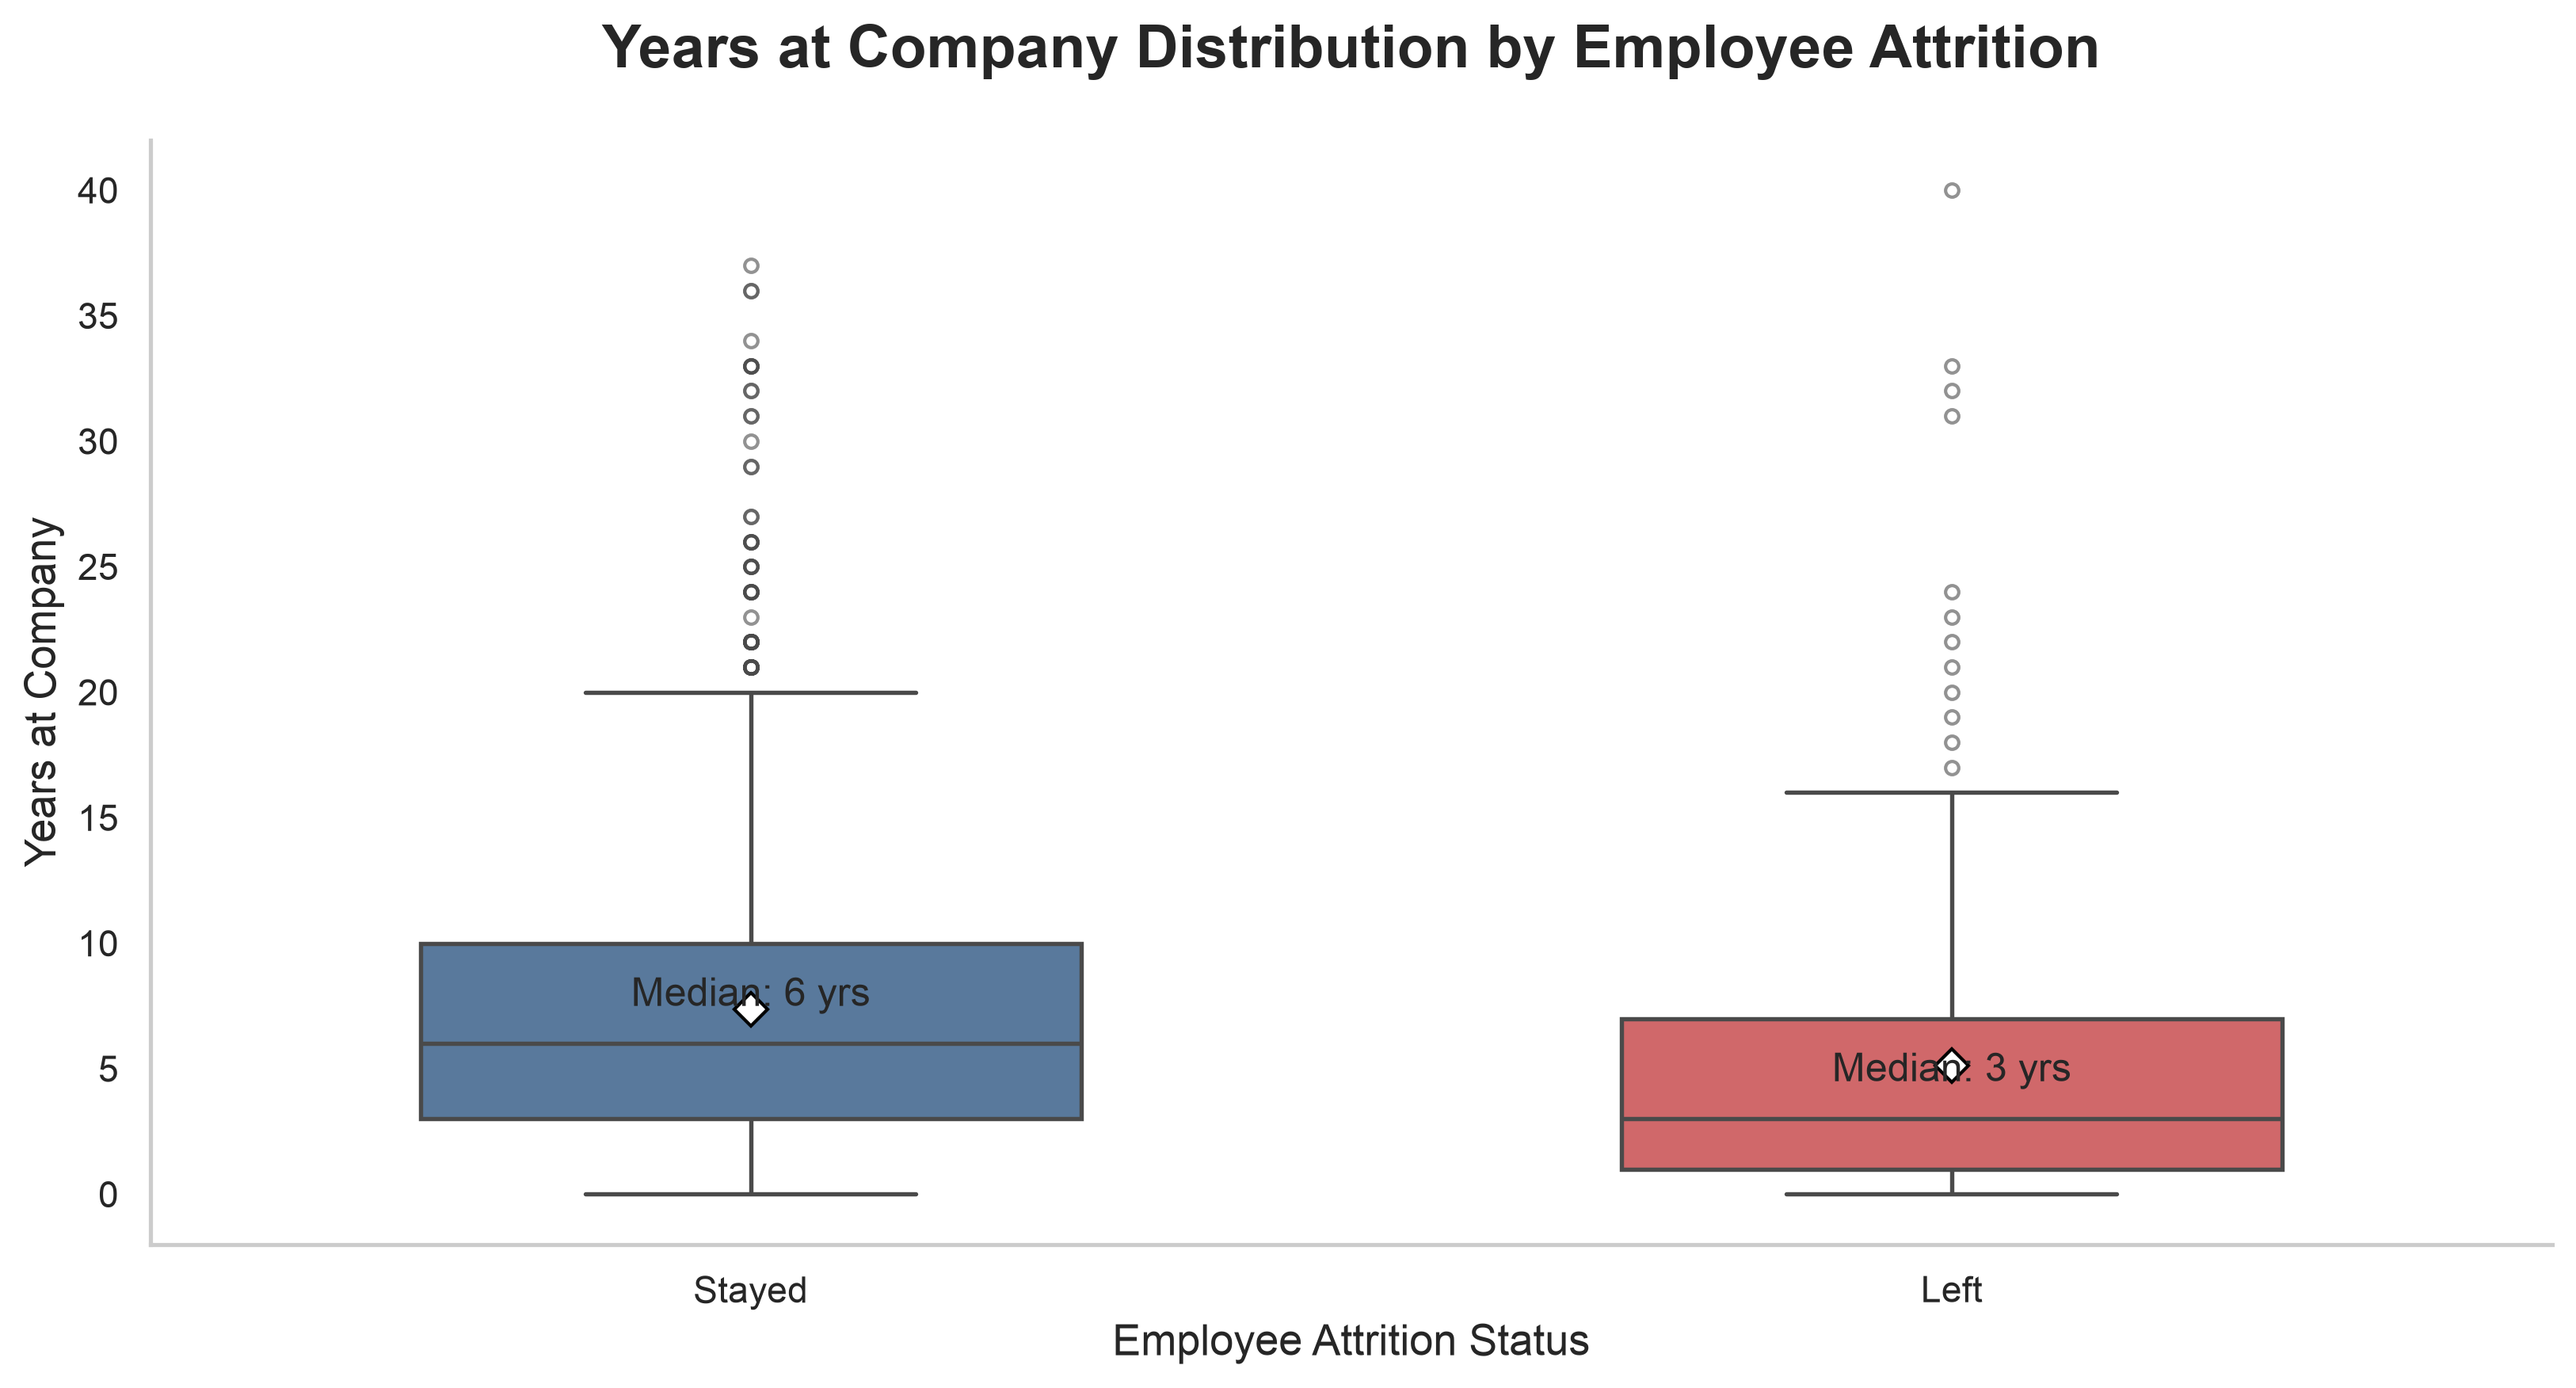

In [13]:
# Compare years at the company between employees who stayed
# and employees who left the organization.
# I want to see whether employees who leave generally have
# fewer years of service.

# Create summary statistics for each attrition group.
tenure_summary = (
    df_clean.groupby("Attrition")["YearsAtCompany"]
    .agg(
        Employee_Count="count",
        Mean_Years="mean",
        Median_Years="median",
        Minimum_Years="min",
        Maximum_Years="max"
    )
    .round(1)
    .reindex(["No", "Yes"])
)

display(tenure_summary)

# Create a professional-quality boxplot.
plt.figure(figsize=(11, 6), dpi=300)

ax = sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="YearsAtCompany",
    hue="Attrition",
    order=["No", "Yes"],
    palette={
        "No": "#4E79A7",
        "Yes": "#E15759"
    },
    width=0.55,
    linewidth=1.3,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7
    },
    flierprops={
        "marker": "o",
        "markersize": 4,
        "alpha": 0.60
    },
    legend=False
)

# Calculate the median years at the company.
median_tenure = (
    df_clean.groupby("Attrition")["YearsAtCompany"]
    .median()
    .reindex(["No", "Yes"])
)

# Display the median above each box.
for position, median in enumerate(median_tenure):

    ax.text(
        position,
        median + 1.5,
        f"Median: {median:.0f} yrs",
        ha="center",
        fontsize=12
    )

plt.title(
    "Years at Company Distribution by Employee Attrition",
    fontsize=18,
    fontweight="bold",
    pad=22
)

plt.xlabel("Employee Attrition Status", fontsize=13)
plt.ylabel("Years at Company", fontsize=13)

plt.xticks(
    ticks=[0, 1],
    labels=["Stayed", "Left"],
    fontsize=11
)

plt.yticks(fontsize=11)

ax.grid(False)
sns.despine()

plt.tight_layout()

plt.show()

### Interpretation

Employees who left the organization generally had fewer years of service than employees who remained. The median tenure of employees who stayed was 6 years, while the median tenure of employees who left was only 3 years. The average tenure also followed a similar pattern, with employees who stayed averaging 7.4 years compared to 5.1 years for employees who left.

Although some long-tenured employees experienced attrition, the overall distribution indicates that turnover occurs more frequently among employees with fewer years at the company. These findings suggest that employee tenure is associated with attrition and may be an important predictor in the predictive models developed later in this project.

## Section 6.9: Job Role and Employee Attrition

Employee turnover may differ across job roles because each position has unique responsibilities, workloads, career advancement opportunities, and compensation structures. Identifying job roles with higher attrition rates can help organizations focus retention efforts where they are most needed. This section examines attrition rates across all job roles to determine whether certain positions experience higher employee turnover.

,Employee Count,Attrition Rate (%)
JobRole,,
Sales Representative,83,39.8
Laboratory Technician,259,23.9
Human Resources,52,23.1
Sales Executive,326,17.5
Research Scientist,292,16.1
Healthcare Representative,131,6.9
Manufacturing Director,145,6.9
Manager,102,4.9
Research Director,80,2.5


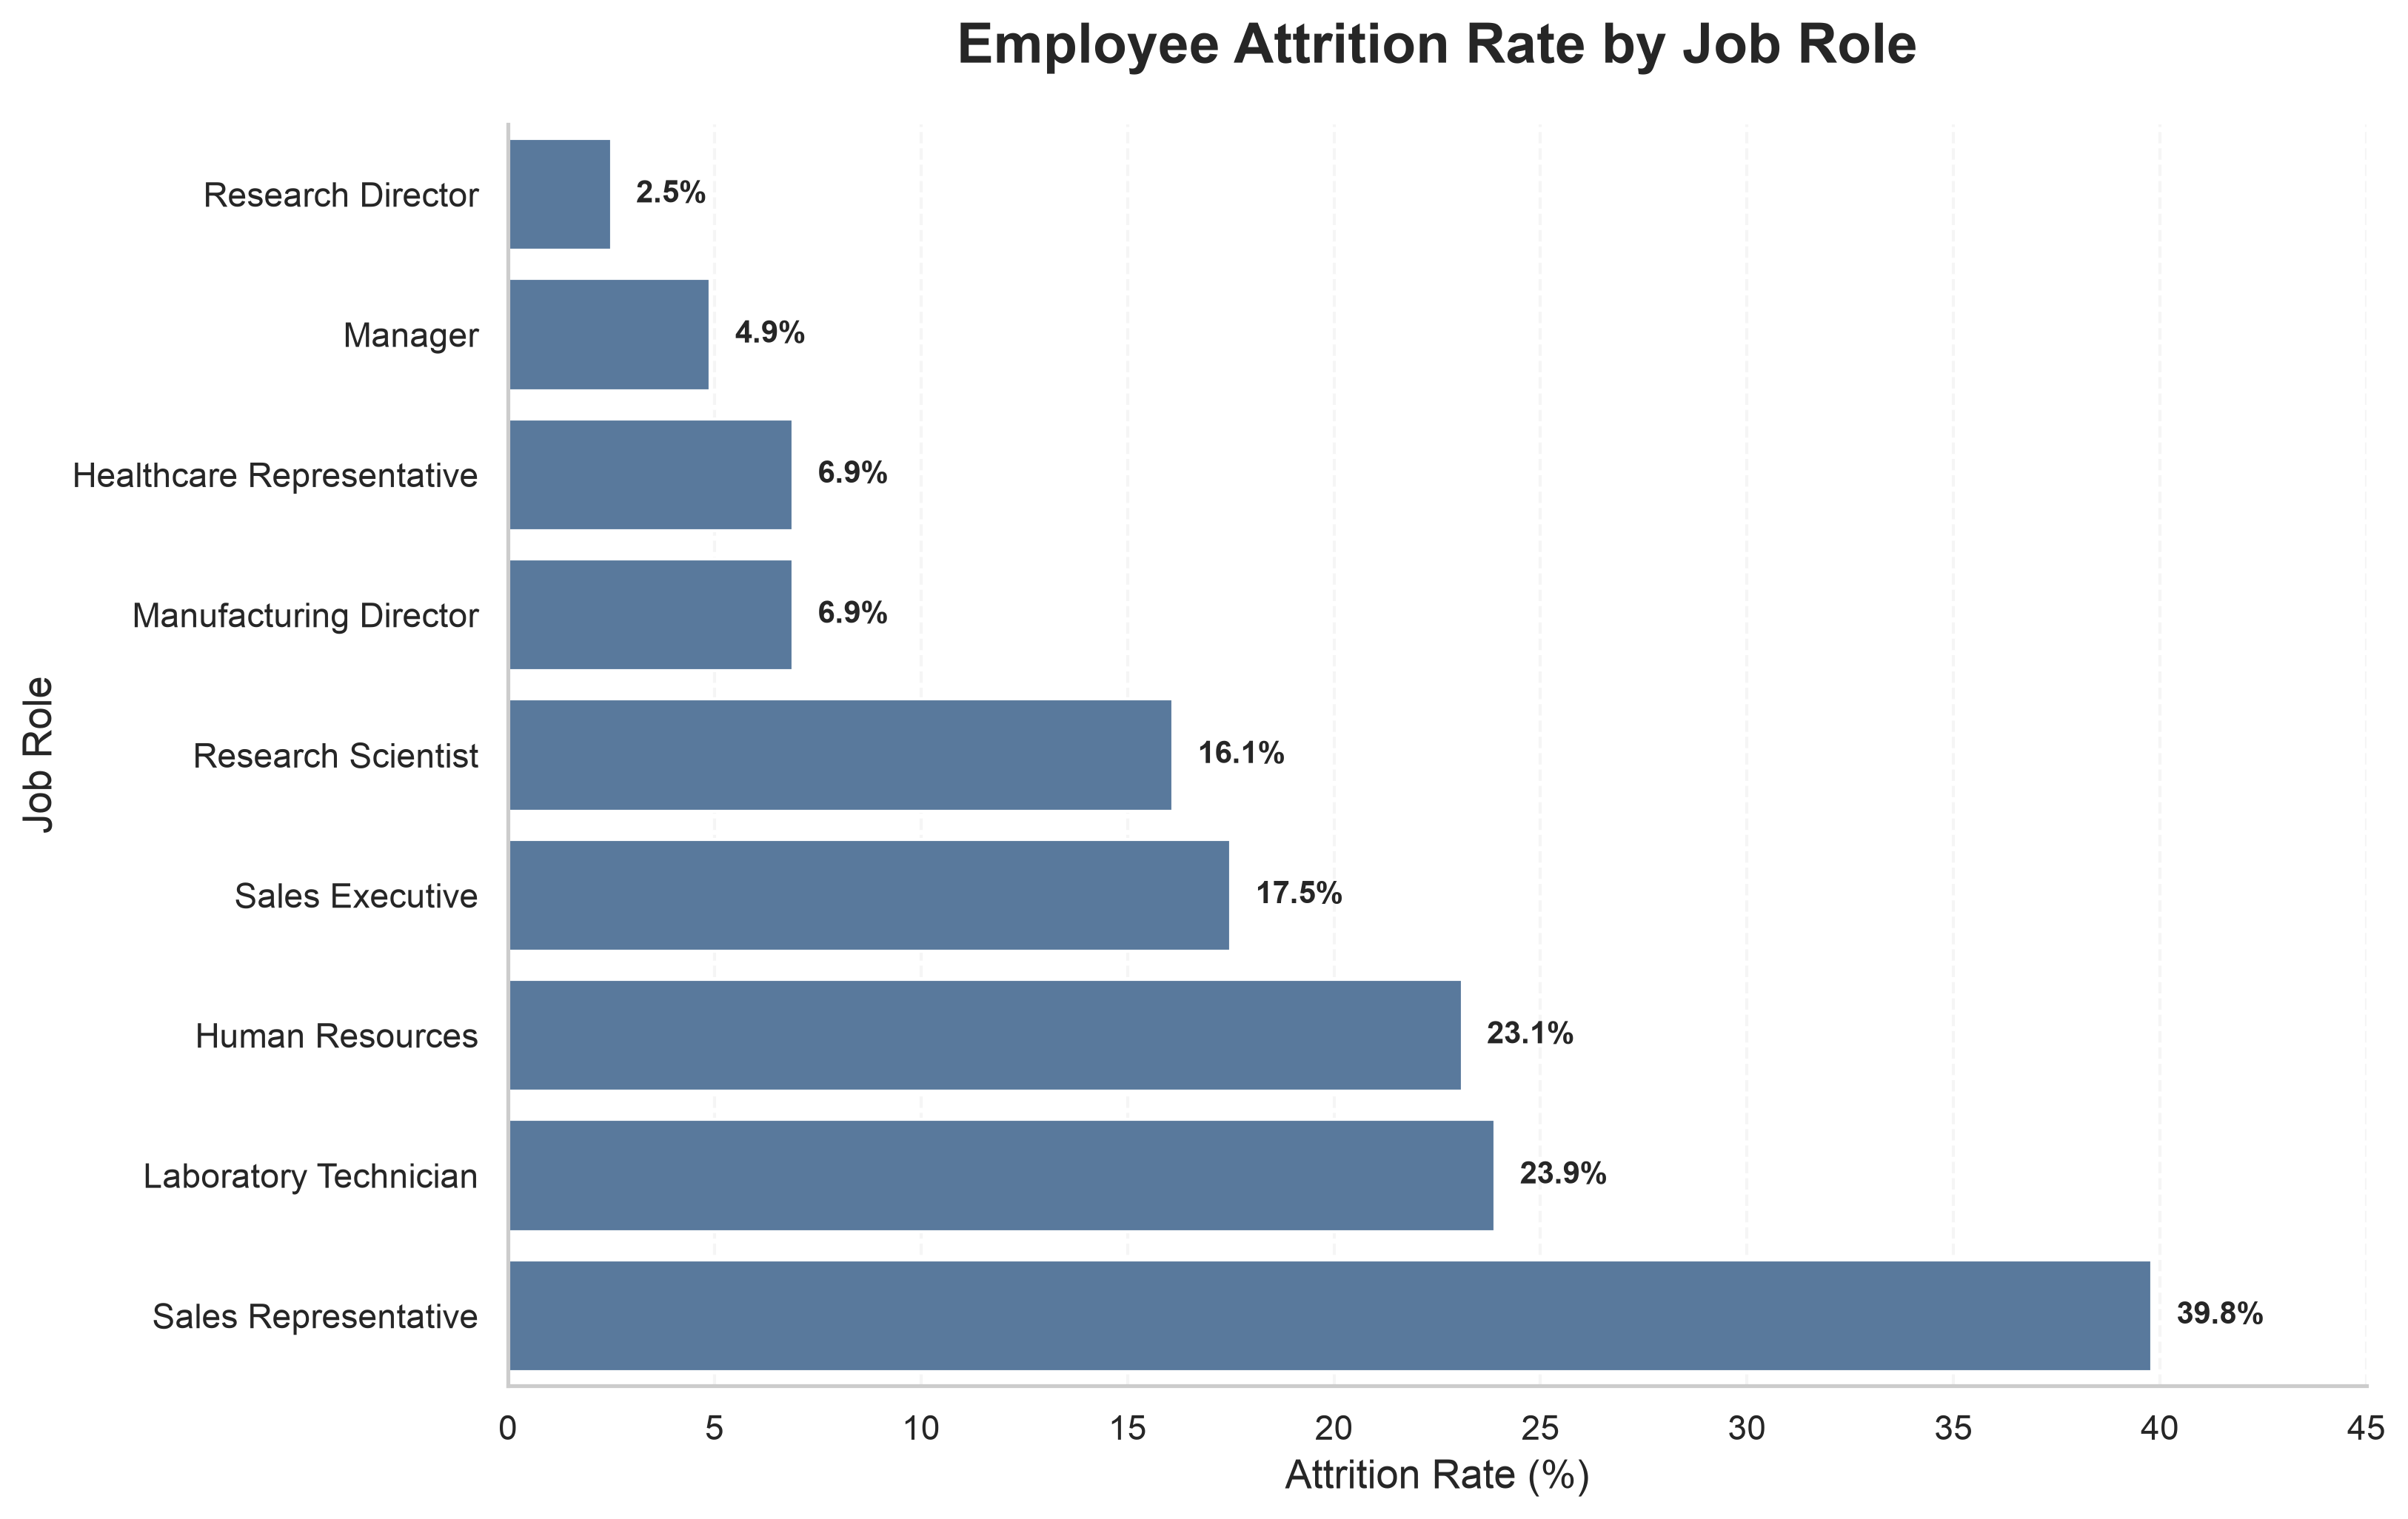

In [14]:
# Compare attrition rates across job roles.
# I want to identify which job roles experience
# the highest employee attrition.

# Calculate the attrition rate for each job role.
jobrole_attrition = (
    pd.crosstab(
        df_clean["JobRole"],
        df_clean["Attrition"],
        normalize="index"
    )["Yes"]
    .mul(100)
    .round(1)
    .sort_values()
)

# Calculate the number of employees in each job role.
jobrole_count = (
    df_clean["JobRole"]
    .value_counts()
    .reindex(jobrole_attrition.index)
)

# Create a summary table.
jobrole_summary = pd.DataFrame({
    "Employee Count": jobrole_count,
    "Attrition Rate (%)": jobrole_attrition
})

display(jobrole_summary.sort_values("Attrition Rate (%)", ascending=False))

# Create a professional-quality horizontal bar chart.
plt.figure(figsize=(11, 7), dpi=300)

ax = sns.barplot(
    data=jobrole_summary,
    y=jobrole_summary.index,
    x="Attrition Rate (%)",
    color="#4E79A7"
)

# Add the attrition rate at the end of each bar.
for bar in ax.patches:

    width = bar.get_width()

    ax.text(
        width + 0.6,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f}%",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Employee Attrition Rate by Job Role",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xlabel("Attrition Rate (%)", fontsize=13)
plt.ylabel("Job Role", fontsize=13)

plt.xlim(0,45)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

ax.grid(axis="x", linestyle="--", alpha=0.18)
sns.despine()

plt.tight_layout()

plt.show()

### Interpretation

Employee attrition varies considerably across job roles. Sales Representatives experienced the highest attrition rate at 39.8 percent, followed by Laboratory Technicians at 23.9 percent and Human Resources employees at 23.1 percent. In contrast, Research Directors and Managers experienced the lowest attrition rates at 2.5 percent and 4.9 percent, respectively.

These findings indicate that employee turnover is not evenly distributed across the organization. Certain job roles appear to experience substantially higher attrition than others, suggesting that role-specific factors such as workload, compensation, career progression, or job expectations may influence employee retention. Job role should therefore be considered an important predictor when developing predictive models and identifying areas where targeted retention strategies may be most effective.

## Section 6.10: Department and Employee Attrition

Departments often differ in workforce size, responsibilities, workload, and organizational structure. Understanding whether employee attrition varies across departments can help identify areas where retention strategies may be most beneficial. This section compares attrition rates across departments to determine whether certain departments experience higher employee turnover.

,Employees,Employees_Left,Attrition Rate (%)
Department,,,
Sales,446,92,20.6
Human Resources,63,12,19.0
Research & Development,961,133,13.8


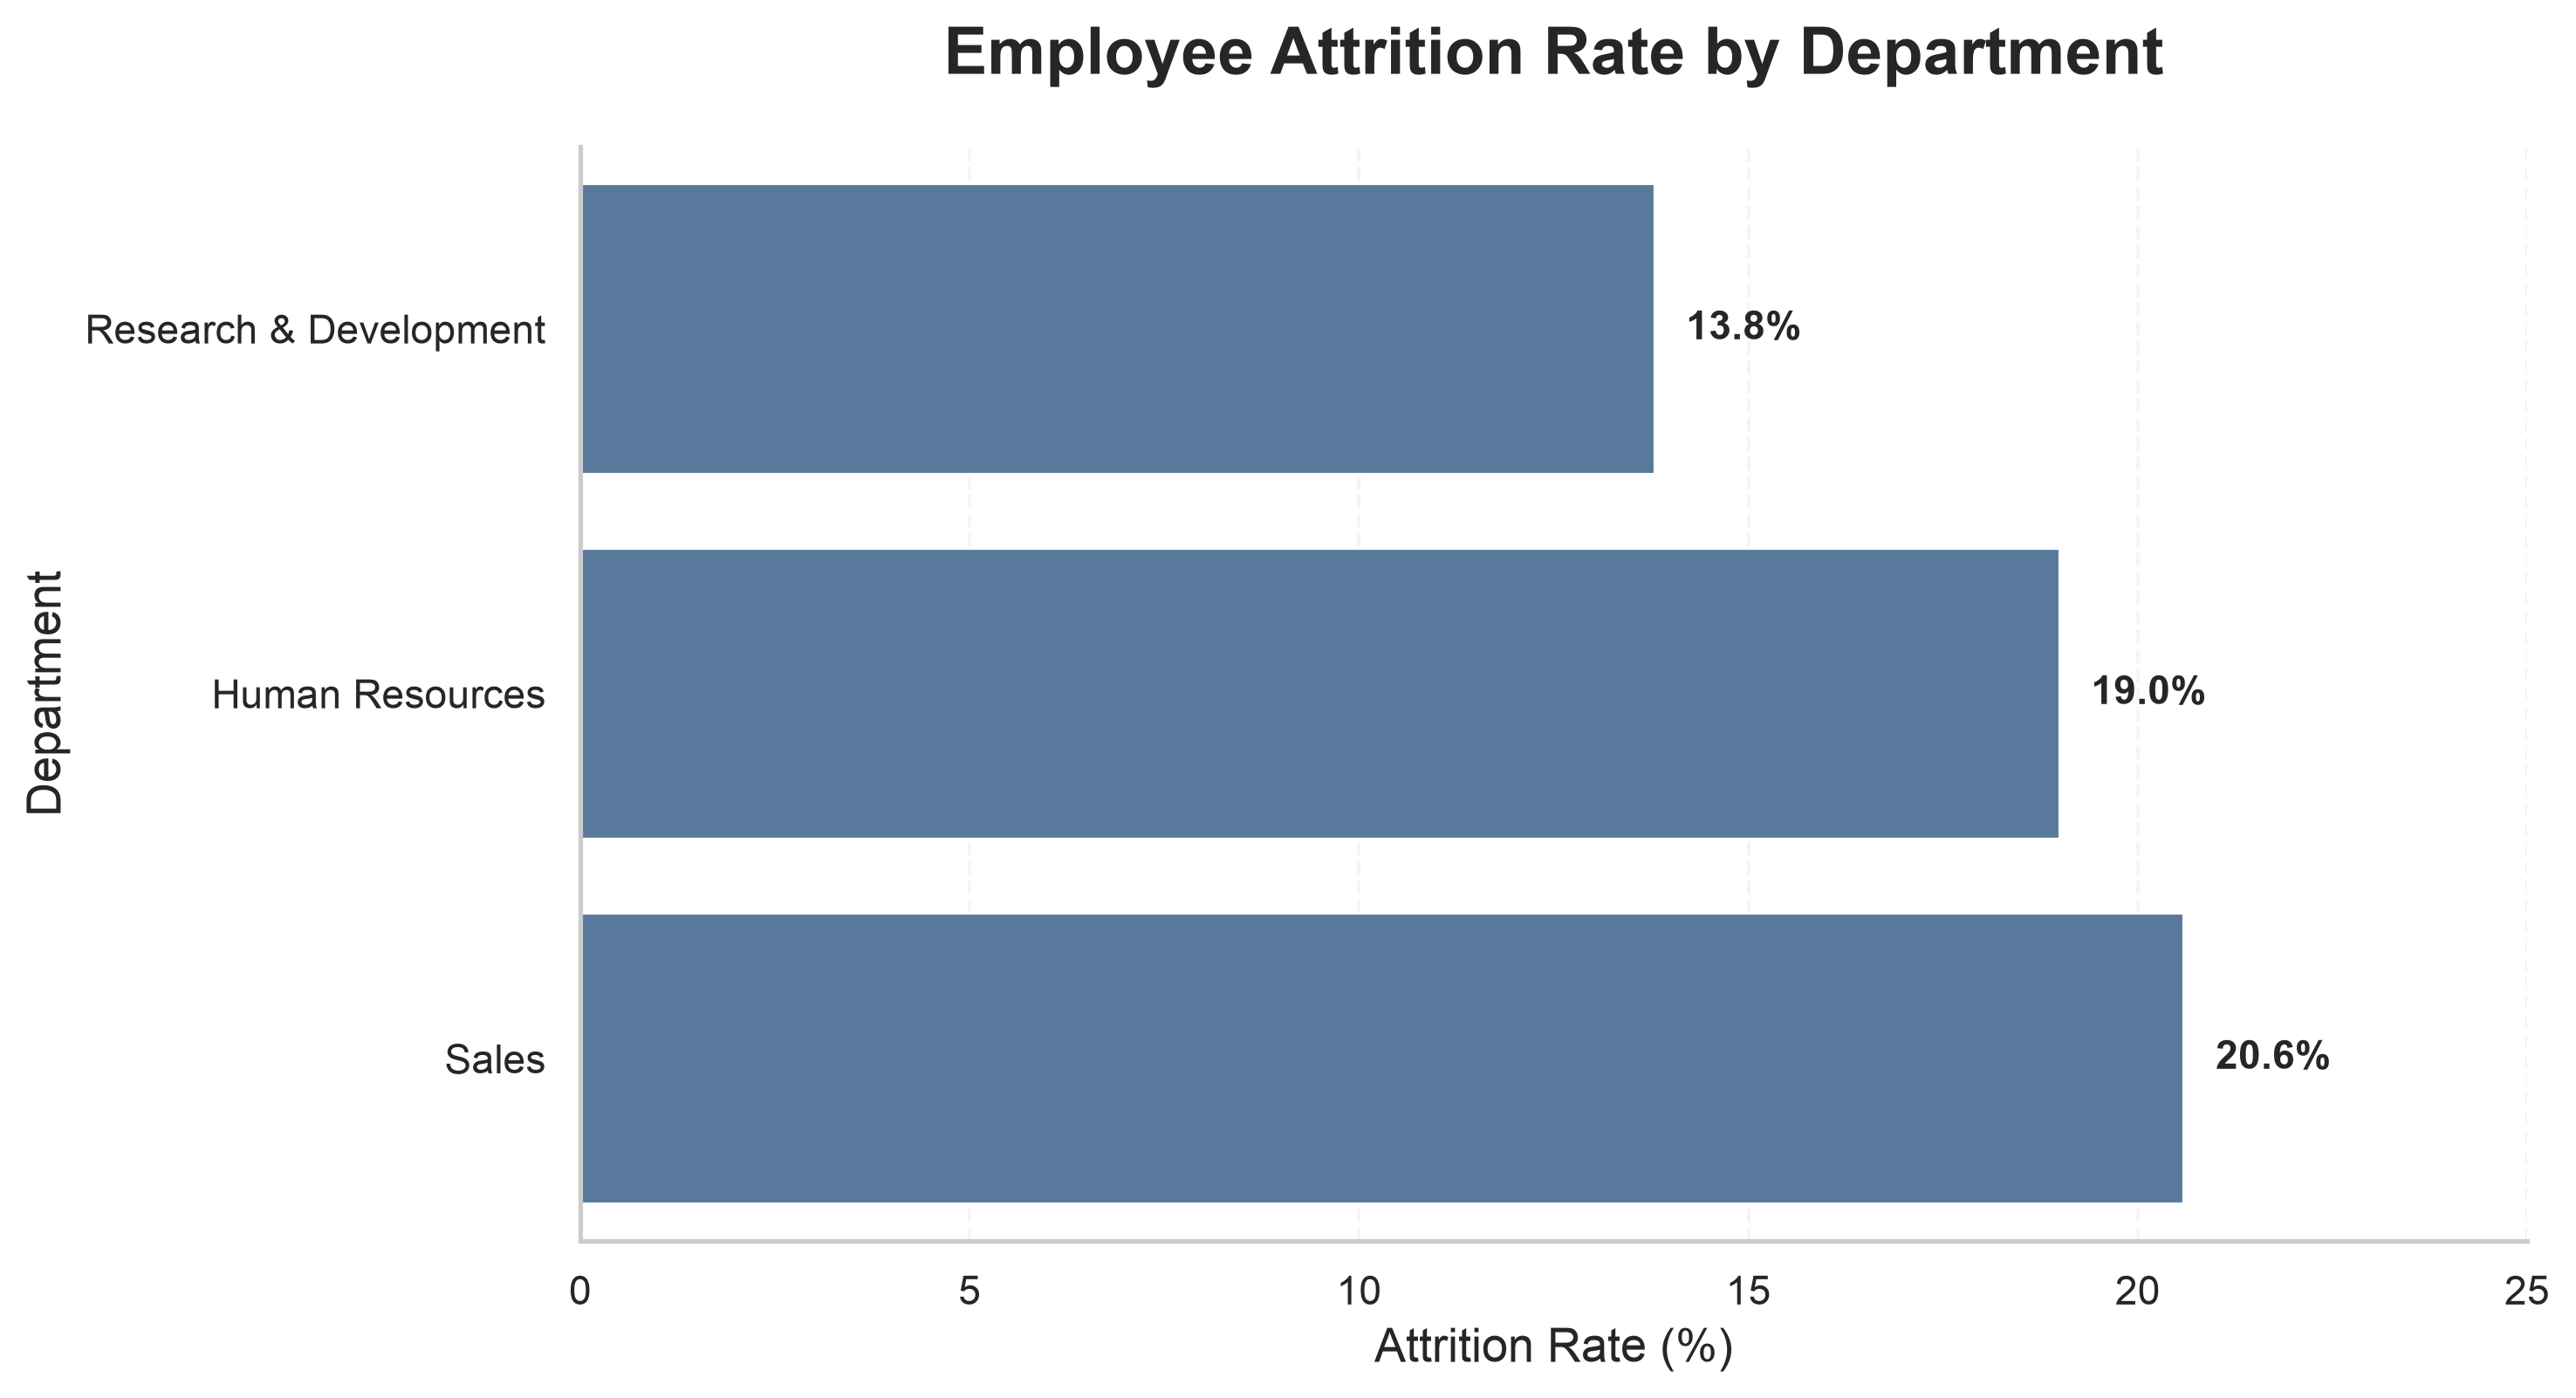

In [15]:
# Compare attrition rates across departments.
# I want to determine whether some departments
# experience higher employee turnover than others.

# Create a summary table showing employee counts,
# employees who left, and attrition rates.

department_summary = (
    df_clean.groupby("Department")
    .agg(
        Employees=("Attrition", "count"),
        Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
    )
)

department_summary["Attrition Rate (%)"] = (
    department_summary["Employees_Left"]
    / department_summary["Employees"]
    * 100
).round(1)

department_summary = (
    department_summary
    .sort_values("Attrition Rate (%)")
)

display(
    department_summary.sort_values(
        "Attrition Rate (%)",
        ascending=False
    )
)

# Create the visualization.
plt.figure(figsize=(10, 5.5), dpi=300)

ax = sns.barplot(
    data=department_summary,
    y=department_summary.index,
    x="Attrition Rate (%)",
    color="#4E79A7"
)

# Add percentage labels.
for bar in ax.patches:

    width = bar.get_width()

    ax.text(
        width + 0.4,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Employee Attrition Rate by Department",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xlabel("Attrition Rate (%)", fontsize=13)
plt.ylabel("Department", fontsize=13)

plt.xlim(0,25)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

ax.grid(axis="x", linestyle="--", alpha=0.18)
sns.despine()

plt.tight_layout()

plt.show()

### Interpretation

Employee attrition varies across departments, although the differences are smaller than those observed across individual job roles. The Sales department experienced the highest attrition rate at 20.6 percent, followed closely by Human Resources at 19.0 percent. Research and Development had the lowest attrition rate at 13.8 percent despite representing the largest department in the organization.

These findings suggest that department membership alone does not fully explain employee turnover. The larger differences observed in the Job Role analysis indicate that specific positions within departments may have a greater influence on attrition than the department itself. As a result, job role is likely to be a stronger predictor of employee attrition than department and should receive greater emphasis during predictive modeling.

## Section 6.11: Correlation Analysis

The final step of the exploratory analysis is to examine the relationships among the numerical variables in the dataset. A correlation matrix helps identify variables that move together, highlights potential multicollinearity, and provides additional insight into which features may contribute useful information during predictive modeling. Understanding these relationships supports both feature selection and model interpretation.

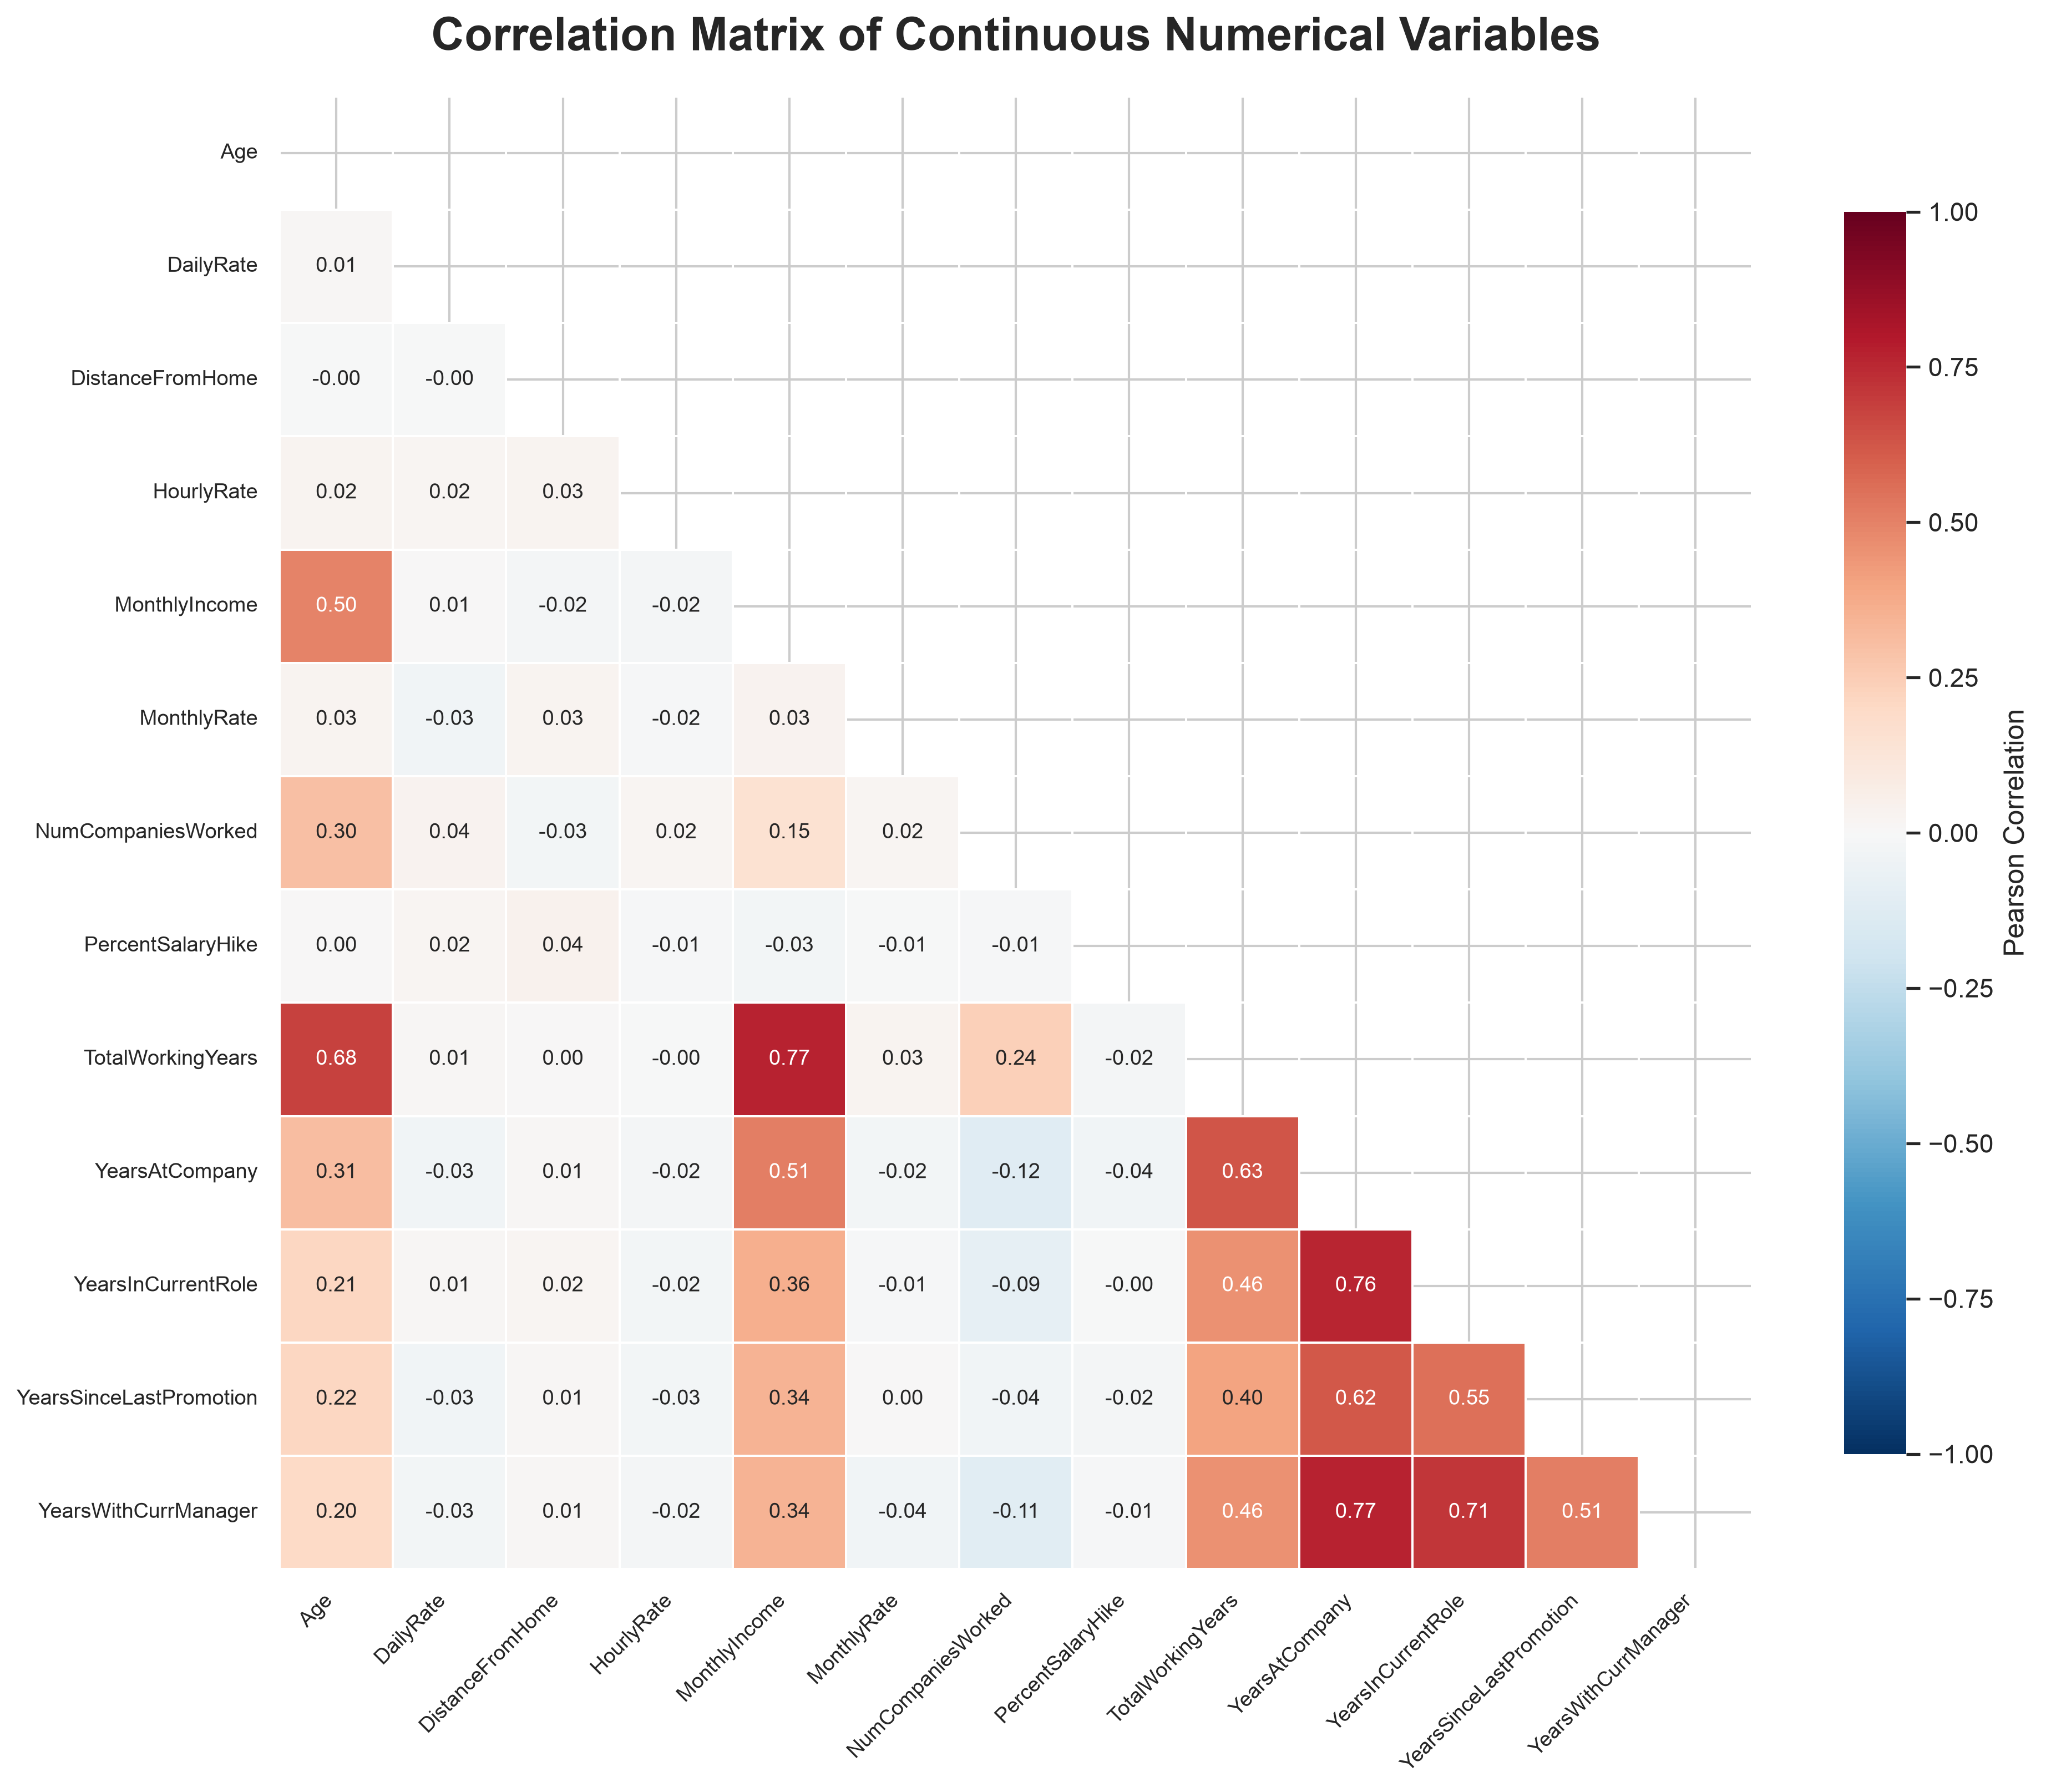

In [16]:
# Examine relationships among the continuous numerical variables.
# I want to identify variables that are highly correlated
# before building predictive models.

continuous_columns = [
    "Age",
    "DailyRate",
    "DistanceFromHome",
    "HourlyRate",
    "MonthlyIncome",
    "MonthlyRate",
    "NumCompaniesWorked",
    "PercentSalaryHike",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager"
]

# Create a dataframe containing only the continuous variables.
continuous_df = df_clean[continuous_columns]

# Calculate the Pearson correlation matrix.
correlation_matrix = continuous_df.corr()

# Mask the upper triangle to remove duplicate information.
mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool)
)

# Create the heatmap.
plt.figure(figsize=(13, 11), dpi=300)

sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 9},
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Pearson Correlation",
        "shrink": 0.80
    }
)

plt.title(
    "Correlation Matrix of Continuous Numerical Variables",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9
)

plt.yticks(
    fontsize=9
)

plt.tight_layout()

plt.show()

### Interpretation

The correlation analysis identified several meaningful relationships among the continuous numerical variables. Monthly income showed a very strong positive correlation with job level (r = 0.95), indicating that employees in higher job levels generally earn higher salaries. Total working years was also strongly correlated with monthly income (r = 0.77) and age (r = 0.68), suggesting that employees with more experience tend to be older and receive higher compensation.

Several tenure-related variables, including Years at Company, Years in Current Role, Years Since Last Promotion, and Years with Current Manager, exhibited moderate to strong positive correlations because they all measure related aspects of employee tenure. These relationships are expected and do not necessarily indicate a problem, but they should be considered when selecting features for predictive modeling. Overall, the correlation matrix suggests limited multicollinearity among most continuous variables while identifying a small number of highly related features that may require additional evaluation during model development.

## Section 6.12: Key Findings from the Exploratory Data Analysis

The exploratory analysis identified several important patterns that help explain employee attrition within the organization. While no single variable completely explains why employees leave, several factors consistently showed meaningful relationships with employee turnover.

The strongest finding was overtime. Employees who regularly worked overtime experienced substantially higher attrition than employees who did not, suggesting that workload and work demands may contribute to employee turnover. Business travel also showed a clear relationship with attrition, as employees who traveled frequently left the organization at much higher rates than employees who rarely or never traveled.

Employee tenure was another important factor. Employees who left the company generally had fewer years of service than employees who remained, indicating that turnover occurs more frequently during the earlier stages of employment. Monthly income showed a similar pattern, with employees who left earning noticeably lower salaries on average than employees who stayed.

Job satisfaction and work-life balance were also associated with employee retention. Employees reporting lower job satisfaction generally experienced higher attrition rates, while poorer work-life balance was associated with increased employee turnover. These findings suggest that both financial and workplace experience factors contribute to employee retention.

Finally, organizational characteristics also influenced attrition. Job role provided considerably more insight than department, indicating that specific positions experience different levels of turnover even within the same department. Overall, the exploratory analysis demonstrates that employee attrition is influenced by a combination of demographic, organizational, financial, and workplace-related factors.

## Section 6.13: Exploratory Analysis Summary

The exploratory analysis confirmed that the data is suitable for answering the business question. Overtime, business travel, tenure, monthly income, job satisfaction, work-life balance, and job role showed the clearest differences between employees who stayed and those who left. These patterns guided the modeling stage, but they remain associations rather than proof of causation.

Because attrition is the minority outcome, the predictive analysis emphasizes recall, precision-recall AUC, and error counts instead of relying on accuracy alone. The next section compares transparent and nonlinear classification models using training-only cross-validation before evaluating one selected model on untouched test data.


## References

Han, J., Kamber, M., & Pei, J. (2022). Data mining: Concepts and techniques (4th ed.). Morgan Kaufmann.

IBM. (n.d.). IBM HR analytics employee attrition & performance. Kaggle. https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). An introduction to statistical learning: With applications in Python (2nd ed.). Springer. https://doi.org/10.1007/978-3-031-38747-0

McKinney, W. (2022). Python for data analysis: Data wrangling with pandas, NumPy, and Jupyter (3rd ed.). O'Reilly Media.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Waskom, M. L. (2021). Seaborn: Statistical data visualization. Journal of Open Source Software, 6(60), Article 3021. https://doi.org/10.21105/joss.03021

# Predictive Modeling and Evaluation

## Purpose

After cleaning and exploring the employee data, I prepare a leakage-safe modeling workflow, compare candidate classifiers, evaluate the selected model once on untouched test data, and interpret both performance and limitations. Because attrition is imbalanced, I examine precision, recall, F1 score, ROC-AUC, precision-recall AUC, confusion matrices, and the practical meaning of prediction errors.


## 7.1 Preparing and Validating the Modeling Data

I rebuild the modeling data from the unchanged source file, verify its expected structure and target labels, repeat the documented cleaning decisions, and separate predictors by data type. These checks protect the analysis from accidental source changes and prepare the data for a leakage-safe pipeline.


In [17]:
# I reload the unchanged source so the modeling stage can be validated independently.
df_raw = pd.read_csv(data_path)

# I confirm the source structure and target labels before preprocessing.
assert df_raw.shape == (1470, 35), (
    f"Unexpected source shape: {df_raw.shape}. The expected shape is 1,470 rows and 35 columns."
)
assert set(df_raw["Attrition"].dropna().unique()) == {"No", "Yes"}

# These three fields are constant, and EmployeeNumber is only an identifier.
excluded_columns = [
    "EmployeeCount",
    "Over18",
    "StandardHours",
    "EmployeeNumber",
]
df_clean = df_raw.drop(columns=excluded_columns).copy()

# I reconcile the cleaned data with the source before modeling.
assert df_clean.shape == (1470, 31)
assert df_clean.isna().sum().sum() == 0
assert df_clean.duplicated().sum() == 0
assert not set(excluded_columns).intersection(df_clean.columns)

modeling_data = df_clean.copy()
modeling_data["Attrition_Flag"] = modeling_data["Attrition"].map({"No": 0, "Yes": 1})
assert modeling_data["Attrition_Flag"].notna().all()

print(f"Validated source shape: {df_raw.shape}")
print(f"Validated modeling shape: {modeling_data.shape}")
print(f"Attrition cases: {int(modeling_data['Attrition_Flag'].sum())}")

# I separate the predictors from the attrition outcome.
X = df_clean.drop(columns="Attrition")
y = df_clean["Attrition"].map({"No": 0, "Yes": 1}).astype("int8")

categorical_features = [
    column for column in X.columns
    if isinstance(X[column].dtype, pd.CategoricalDtype)
    or pd.api.types.is_string_dtype(X[column])
]
numeric_features = [
    column for column in X.columns
    if pd.api.types.is_numeric_dtype(X[column])
]

# I check that every predictor belongs to exactly one feature group.
assert len(categorical_features) + len(numeric_features) == X.shape[1]
assert y.isna().sum() == 0

modeling_validation = pd.DataFrame({
    "Validation Check": [
        "Original observations", "Original columns",
        "Modeling observations", "Predictor columns",
        "Numerical predictors", "Categorical predictors",
        "Missing predictor values", "Duplicate modeling records",
        "Employees who left", "Attrition rate"
    ],
    "Result": [
        f"{df_raw.shape[0]:,}", f"{df_raw.shape[1]:,}",
        f"{df_clean.shape[0]:,}", f"{X.shape[1]:,}",
        f"{len(numeric_features):,}", f"{len(categorical_features):,}",
        f"{X.isna().sum().sum():,}", f"{df_clean.duplicated().sum():,}",
        f"{y.sum():,}", f"{y.mean() * 100:.2f}%"
    ]
})

print(f"Dataset loaded from: {data_path}")
print("\nModeling data validation:")
display(modeling_validation)
print("\nCategorical predictors:")
print(categorical_features)
print("\nNumerical predictors:")
print(numeric_features)


Validated source shape: (1470, 35)
Validated modeling shape: (1470, 32)
Attrition cases: 237
Dataset loaded from: data/WA_Fn-UseC_-HR-Employee-Attrition.csv

Modeling data validation:


,Validation Check,Result
0,Original observations,"1,470"
1,Original columns,35
2,Modeling observations,"1,470"
3,Predictor columns,30
4,Numerical predictors,23
5,Categorical predictors,7
6,Missing predictor values,0
7,Duplicate modeling records,0
8,Employees who left,237
9,Attrition rate,16.12%



Categorical predictors:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical predictors:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


## 7.2 Creating the Training and Test Sets

In [18]:
# I am importing the tools needed to create the training and test sets
# and prepare different types of predictors without introducing data leakage.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# I am reserving 20% of the employee records for final model evaluation.
# Stratification preserves the attrition rate in both datasets because
# employees who left represent a relatively small proportion of the sample.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# I am creating a numerical preprocessing pipeline.
# The imputer protects against unexpected missing values, while scaling
# prevents variables with larger measurement ranges from dominating
# models such as logistic regression.
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# I am creating a categorical preprocessing pipeline.
# Unknown categories are ignored so future data can be processed safely.
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "one_hot_encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="if_binary"
            )
        )
    ]
)

# I am combining both preprocessing pipelines.
# This object is defined now but will only be fitted to the training data
# inside each model pipeline, which prevents information leakage.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# I am verifying that the training and test sets contain different employees
# and that every original modeling record is represented exactly once.
assert len(X_train) + len(X_test) == len(X)
assert X_train.index.intersection(X_test.index).empty
assert X_train.shape[1] == X_test.shape[1] == X.shape[1]

# I am confirming that stratification preserved the target distribution.
assert abs(y_train.mean() - y_test.mean()) < 0.01

# I am summarizing the split so the sample sizes and class balance
# are transparent before any model is trained.
split_summary = pd.DataFrame({
    "Dataset": [
        "Complete Modeling Data",
        "Training Set",
        "Test Set"
    ],
    "Observations": [
        len(X),
        len(X_train),
        len(X_test)
    ],
    "Employees Who Stayed": [
        int((y == 0).sum()),
        int((y_train == 0).sum()),
        int((y_test == 0).sum())
    ],
    "Employees Who Left": [
        int(y.sum()),
        int(y_train.sum()),
        int(y_test.sum())
    ],
    "Attrition Rate": [
        f"{y.mean() * 100:.2f}%",
        f"{y_train.mean() * 100:.2f}%",
        f"{y_test.mean() * 100:.2f}%"
    ]
})

print("Training and Test Set Validation:")
display(split_summary)

print(f"\nTraining predictors: {X_train.shape}")
print(f"Test predictors: {X_test.shape}")
print(
    "Overlapping employee indexes:",
    len(X_train.index.intersection(X_test.index))
)

print(
    "\nThe preprocessing pipeline has been defined but not fitted. "
    "It will be fitted only through the training-data model pipelines."
)

Training and Test Set Validation:


,Dataset,Observations,Employees Who Stayed,Employees Who Left,Attrition Rate
0,Complete Modeling Data,1470,1233,237,16.12%
1,Training Set,1176,986,190,16.16%
2,Test Set,294,247,47,15.99%



Training predictors: (1176, 30)
Test predictors: (294, 30)
Overlapping employee indexes: 0

The preprocessing pipeline has been defined but not fitted. It will be fitted only through the training-data model pipelines.


### Interpretation
The stratified split was successful. The training set contains 1,176 employees and the test set contains 294, preserving nearly identical attrition rates of 16.16% and 15.99%. There are no overlapping employee indexes, which confirms that the same record cannot appear in both datasets. The preprocessing pipeline has only been defined—not fitted—so scaling, imputation, and categorical encoding will be learned exclusively from training data, preventing leakage from the untouched test set.

## 7.3 Comparing Candidate Models with Cross-Validation

In [19]:
# I am importing a transparent baseline and two classification models
# so I can compare simple and more flexible predictive approaches.
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# I am importing metrics that reflect the imbalanced attrition outcome.
# Accuracy alone could appear high simply by predicting that everyone stays.
from sklearn.metrics import (
    f1_score,
    make_scorer,
    precision_score,
    recall_score
)

from sklearn.model_selection import StratifiedKFold, cross_validate

# I am creating a baseline that predicts according to the training-set
# class distribution. A useful model should clearly outperform this baseline.
candidate_models = {
    "Dummy Baseline": DummyClassifier(
        strategy="prior"
    ),

    # I am using balanced class weights so employees who left
    # receive greater importance during model training.
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    # I am including a nonlinear model so I can determine whether
    # interactions and more complex relationships improve prediction.
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# I am defining metrics that measure ranking quality, minority-class
# performance, and the balance between identifying departures and false alerts.
scoring_metrics = {
    "ROC_AUC": "roc_auc",
    "PR_AUC": "average_precision",
    "Balanced_Accuracy": "balanced_accuracy",
    "Precision": make_scorer(
        precision_score,
        zero_division=0
    ),
    "Recall": make_scorer(
        recall_score,
        zero_division=0
    ),
    "F1": make_scorer(
        f1_score,
        zero_division=0
    )
}

# I am using five stratified folds so every validation fold preserves
# approximately the same employee attrition rate.
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model_pipelines = {}
validation_rows = []

# I am comparing every model with preprocessing fitted independently
# inside each training fold. This prevents validation information
# from influencing scaling, imputation, encoding, or model training.
for model_name, classifier in candidate_models.items():

    model_pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                classifier
            )
        ]
    )

    model_pipelines[model_name] = model_pipeline

    validation_scores = cross_validate(
        estimator=model_pipeline,
        X=X_train,
        y=y_train,
        cv=cross_validation,
        scoring=scoring_metrics,
        return_train_score=False,
        n_jobs=1
    )

    model_results = {
        "Model": model_name
    }

    # I am reporting both the average performance and variation
    # across folds so model stability is visible.
    for metric_name in scoring_metrics:
        fold_scores = validation_scores[f"test_{metric_name}"]

        model_results[f"{metric_name} Mean"] = fold_scores.mean()
        model_results[f"{metric_name} SD"] = fold_scores.std(ddof=1)

    validation_rows.append(model_results)

# I am ranking models by average ROC-AUC while also examining
# precision-recall performance because attrition is imbalanced.
model_comparison = (
    pd.DataFrame(validation_rows)
    .sort_values(
        by=["ROC_AUC Mean", "PR_AUC Mean"],
        ascending=False
    )
    .reset_index(drop=True)
)

# I am selecting the best validated model without using the test set.
selected_model_name = model_comparison.loc[0, "Model"]
selected_model_pipeline = model_pipelines[selected_model_name]

# I am confirming that a predictive model outperformed the baseline.
assert selected_model_name != "Dummy Baseline"
assert model_comparison.loc[0, "ROC_AUC Mean"] > 0.50

print("Five-Fold Training-Set Cross-Validation Results:")

display(
    model_comparison.style.format({
        column: "{:.3f}"
        for column in model_comparison.columns
        if column != "Model"
    })
)

print(f"\nSelected Model: {selected_model_name}")

print(
    "\nThe test set has not been used for model training, "
    "comparison, or selection."
)

Five-Fold Training-Set Cross-Validation Results:


,Model,ROC_AUC Mean,ROC_AUC SD,PR_AUC Mean,PR_AUC SD,Balanced_Accuracy Mean,Balanced_Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,F1 Mean,F1 SD
0,Logistic Regression,0.827,0.032,0.605,0.092,0.746,0.029,0.371,0.042,0.737,0.070,0.492,0.037
1,Random Forest,0.810,0.038,0.567,0.087,0.677,0.062,0.626,0.151,0.400,0.128,0.481,0.127
2,Dummy Baseline,0.500,0.000,0.162,0.000,0.500,0.000,0.000,0.000,0.000,0.000,0.000,0.000



Selected Model: Logistic Regression

The test set has not been used for model training, comparison, or selection.


### Interpretation
Logistic Regression produced the strongest training-only validation results, with mean ROC-AUC of 0.827 and PR-AUC of 0.605. Its ROC-AUC exceeded Random Forest by 0.017, while its recall was substantially higher: 73.7% compared with 40.0%. Random Forest was more precise, but it missed considerably more employees who left. Logistic Regression is therefore the more defensible screening model when the purpose is to identify employees who may need attention, while recognizing that its lower precision will create more false alerts. The untouched test set was not involved in this decision.

## 7.4 Evaluating the Selected Model on the Test Set

Final Selected Model: Logistic Regression
Untouched Test Observations: 294

Final Test-Set Performance:


,Performance Measure,Test Estimate,95% CI Lower,95% CI Upper
0,Accuracy,0.752,0.701,0.799
1,Balanced Accuracy,0.706,0.629,0.774
2,Precision,0.349,0.277,0.419
3,Recall,0.638,0.489,0.766
4,F1 Score,0.451,0.361,0.533
5,ROC-AUC,0.802,0.724,0.866
6,PR-AUC,0.557,0.439,0.669



Classification Summary:


,precision,recall,f1-score,support
Stayed,0.918,0.773,0.840,247
Left,0.349,0.638,0.451,47
accuracy,0.752,0.752,0.752,1
macro avg,0.634,0.706,0.645,294
weighted avg,0.827,0.752,0.777,294


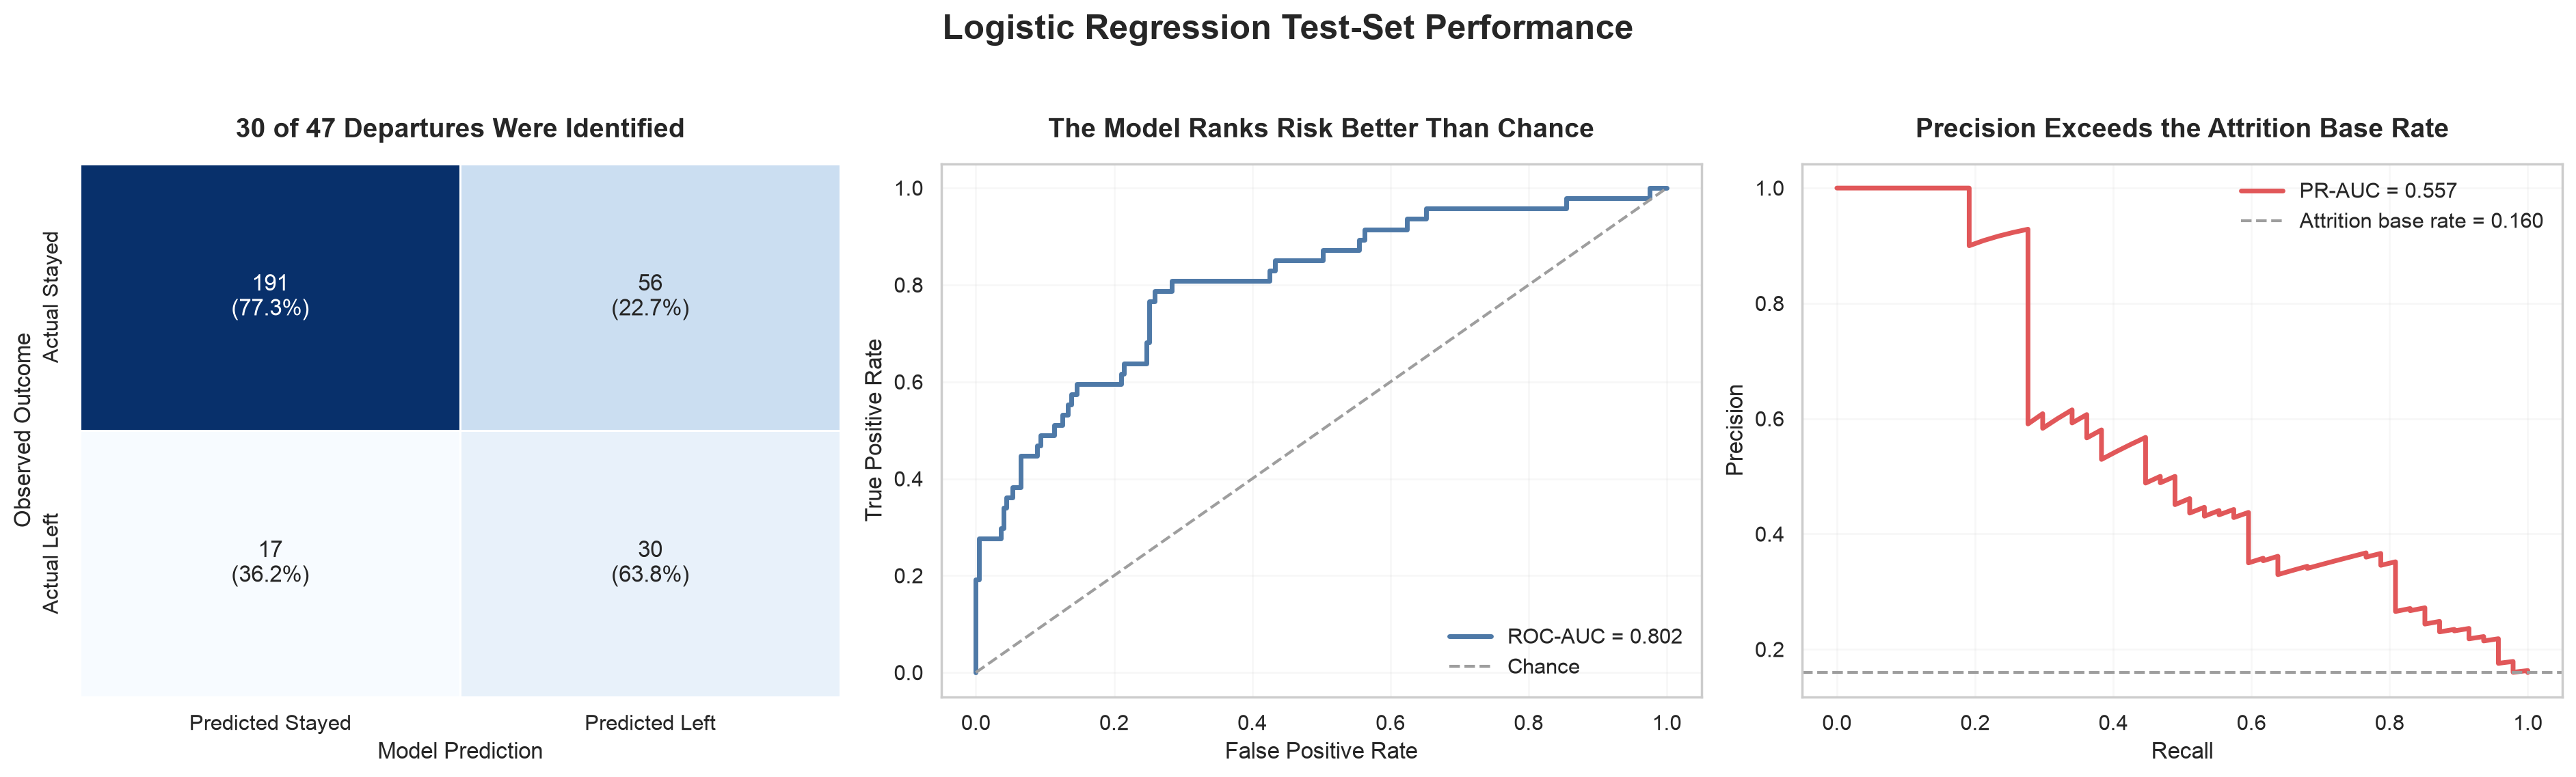


Confusion Matrix Counts:
Correctly predicted stayers: 191
Stayers incorrectly flagged: 56
Departures missed: 17
Departures identified: 30


In [20]:
# I am importing the metrics needed to evaluate classification performance
# from several perspectives instead of relying only on accuracy.
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)

# I am fitting the selected pipeline to the complete training set.
# The preprocessing steps are learned only from the training records.
final_model = selected_model_pipeline

final_model.fit(
    X_train,
    y_train
)

# I am generating one final set of predictions from the untouched test set.
test_predictions = final_model.predict(X_test)

test_probabilities = final_model.predict_proba(X_test)[:, 1]

# I am calculating multiple performance measures because the attrition
# outcome is imbalanced and each metric answers a different question.
test_metric_values = {
    "Accuracy": accuracy_score(
        y_test,
        test_predictions
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test,
        test_predictions
    ),
    "Precision": precision_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "F1 Score": f1_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        test_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_test,
        test_probabilities
    )
}

# I am using a stratified bootstrap to estimate the uncertainty around
# each test metric while preserving the observed class composition.
bootstrap_iterations = 2000
random_generator = np.random.default_rng(42)

actual_values = y_test.to_numpy()
probability_values = test_probabilities

positive_indexes = np.flatnonzero(actual_values == 1)
negative_indexes = np.flatnonzero(actual_values == 0)

bootstrap_results = {
    metric_name: []
    for metric_name in test_metric_values
}

for iteration in range(bootstrap_iterations):

    sampled_positive_indexes = random_generator.choice(
        positive_indexes,
        size=len(positive_indexes),
        replace=True
    )

    sampled_negative_indexes = random_generator.choice(
        negative_indexes,
        size=len(negative_indexes),
        replace=True
    )

    sampled_indexes = np.concatenate([
        sampled_positive_indexes,
        sampled_negative_indexes
    ])

    random_generator.shuffle(sampled_indexes)

    sampled_actual = actual_values[sampled_indexes]
    sampled_probabilities = probability_values[sampled_indexes]
    sampled_predictions = (
        sampled_probabilities >= 0.50
    ).astype(int)

    iteration_metrics = {
        "Accuracy": accuracy_score(
            sampled_actual,
            sampled_predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            sampled_actual,
            sampled_predictions
        ),
        "Precision": precision_score(
            sampled_actual,
            sampled_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            sampled_actual,
            sampled_predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            sampled_actual,
            sampled_predictions,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            sampled_actual,
            sampled_probabilities
        ),
        "PR-AUC": average_precision_score(
            sampled_actual,
            sampled_probabilities
        )
    }

    for metric_name, metric_value in iteration_metrics.items():
        bootstrap_results[metric_name].append(metric_value)

# I am creating a table that reports the test estimate together with
# its 95% bootstrap confidence interval.
test_performance_rows = []

for metric_name, point_estimate in test_metric_values.items():

    lower_limit, upper_limit = np.percentile(
        bootstrap_results[metric_name],
        [2.5, 97.5]
    )

    test_performance_rows.append({
        "Performance Measure": metric_name,
        "Test Estimate": point_estimate,
        "95% CI Lower": lower_limit,
        "95% CI Upper": upper_limit
    })

test_performance = pd.DataFrame(test_performance_rows)

print(f"Final Selected Model: {selected_model_name}")
print(f"Untouched Test Observations: {len(y_test):,}")
print("\nFinal Test-Set Performance:")

display(
    test_performance.style.format({
        "Test Estimate": "{:.3f}",
        "95% CI Lower": "{:.3f}",
        "95% CI Upper": "{:.3f}"
    })
)

# I am displaying the class-level results so I can see how differently
# the model performs for employees who stayed and employees who left.
classification_summary = pd.DataFrame(
    classification_report(
        y_test,
        test_predictions,
        target_names=[
            "Stayed",
            "Left"
        ],
        output_dict=True,
        zero_division=0
    )
).transpose()

print("\nClassification Summary:")

display(
    classification_summary.style.format({
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1-score": "{:.3f}",
        "support": "{:.0f}"
    })
)

# I am creating the confusion matrix and curve data for a visual
# explanation of where the model succeeds and where errors remain.
confusion_counts = confusion_matrix(
    y_test,
    test_predictions
)

row_percentages = (
    confusion_counts
    / confusion_counts.sum(axis=1, keepdims=True)
    * 100
)

confusion_annotations = np.array([
    [
        f"{confusion_counts[row, column]:,}\n"
        f"({row_percentages[row, column]:.1f}%)"
        for column in range(2)
    ]
    for row in range(2)
])

false_positive_rate, true_positive_rate, _ = roc_curve(
    y_test,
    test_probabilities
)

curve_precision, curve_recall, _ = precision_recall_curve(
    y_test,
    test_probabilities
)

# I am creating one connected evaluation story:
# classification errors, ranking quality, and minority-class performance.
fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 5.5),
    dpi=200
)

sns.heatmap(
    confusion_counts,
    annot=confusion_annotations,
    fmt="",
    cmap="Blues",
    cbar=False,
    linewidths=1,
    linecolor="white",
    xticklabels=[
        "Predicted Stayed",
        "Predicted Left"
    ],
    yticklabels=[
        "Actual Stayed",
        "Actual Left"
    ],
    ax=axes[0]
)

axes[0].set_title(
    "30 of 47 Departures Were Identified",
    fontsize=14,
    fontweight="bold",
    pad=14
)

axes[0].set_xlabel("Model Prediction")
axes[0].set_ylabel("Observed Outcome")

axes[1].plot(
    false_positive_rate,
    true_positive_rate,
    color="#4E79A7",
    linewidth=2.5,
    label=f"ROC-AUC = {test_metric_values['ROC-AUC']:.3f}"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="#9E9E9E",
    label="Chance"
)

axes[1].set_title(
    "The Model Ranks Risk Better Than Chance",
    fontsize=14,
    fontweight="bold",
    pad=14
)

axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(frameon=False, loc="lower right")
axes[1].grid(alpha=0.15)

axes[2].plot(
    curve_recall,
    curve_precision,
    color="#E15759",
    linewidth=2.5,
    label=f"PR-AUC = {test_metric_values['PR-AUC']:.3f}"
)

axes[2].axhline(
    y=y_test.mean(),
    linestyle="--",
    color="#9E9E9E",
    label=f"Attrition base rate = {y_test.mean():.3f}"
)

axes[2].set_title(
    "Precision Exceeds the Attrition Base Rate",
    fontsize=14,
    fontweight="bold",
    pad=14
)

axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend(frameon=False, loc="upper right")
axes[2].grid(alpha=0.15)

fig.suptitle(
    "Logistic Regression Test-Set Performance",
    fontsize=18,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.show()

print("\nConfusion Matrix Counts:")
print(f"Correctly predicted stayers: {confusion_counts[0, 0]:,}")
print(f"Stayers incorrectly flagged: {confusion_counts[0, 1]:,}")
print(f"Departures missed: {confusion_counts[1, 0]:,}")
print(f"Departures identified: {confusion_counts[1, 1]:,}")

### Interpretation
The final model achieved a test ROC-AUC of 0.802, showing that it ranks employees who left above employees who stayed substantially better than chance. Its PR-AUC of 0.557 is also more than three times the 15.99% attrition base rate. At the 0.50 threshold, the model identified 30 of the 47 departures, producing 63.8% recall, but it missed 17 departures and incorrectly flagged 56 employees who stayed. Precision was therefore only 34.9%, meaning approximately one in three flagged employees actually left.
The model is most appropriate as an early-warning screening tool—not an automated employment decision system. Its predictions could guide supportive conversations or further review, but the uncertainty intervals and false-positive rate show that individual predictions should not be treated as facts. Overall accuracy of 75.2% is less informative here because predicting that everyone stayed would achieve 84.0% accuracy while identifying no departures.

## 7.5 Identifying the Most Influential Predictors

Permutation importance on the untouched test set:


,Predictor,Mean Decrease in ROC-AUC,Standard Deviation
0,OverTime,0.105,0.014
1,MaritalStatus,0.024,0.008
2,YearsSinceLastPromotion,0.024,0.009
3,NumCompaniesWorked,0.023,0.011
4,BusinessTravel,0.020,0.009
5,JobSatisfaction,0.019,0.010
6,JobRole,0.015,0.014
7,TrainingTimesLastYear,0.013,0.005
8,EnvironmentSatisfaction,0.013,0.010
9,JobInvolvement,0.012,0.007


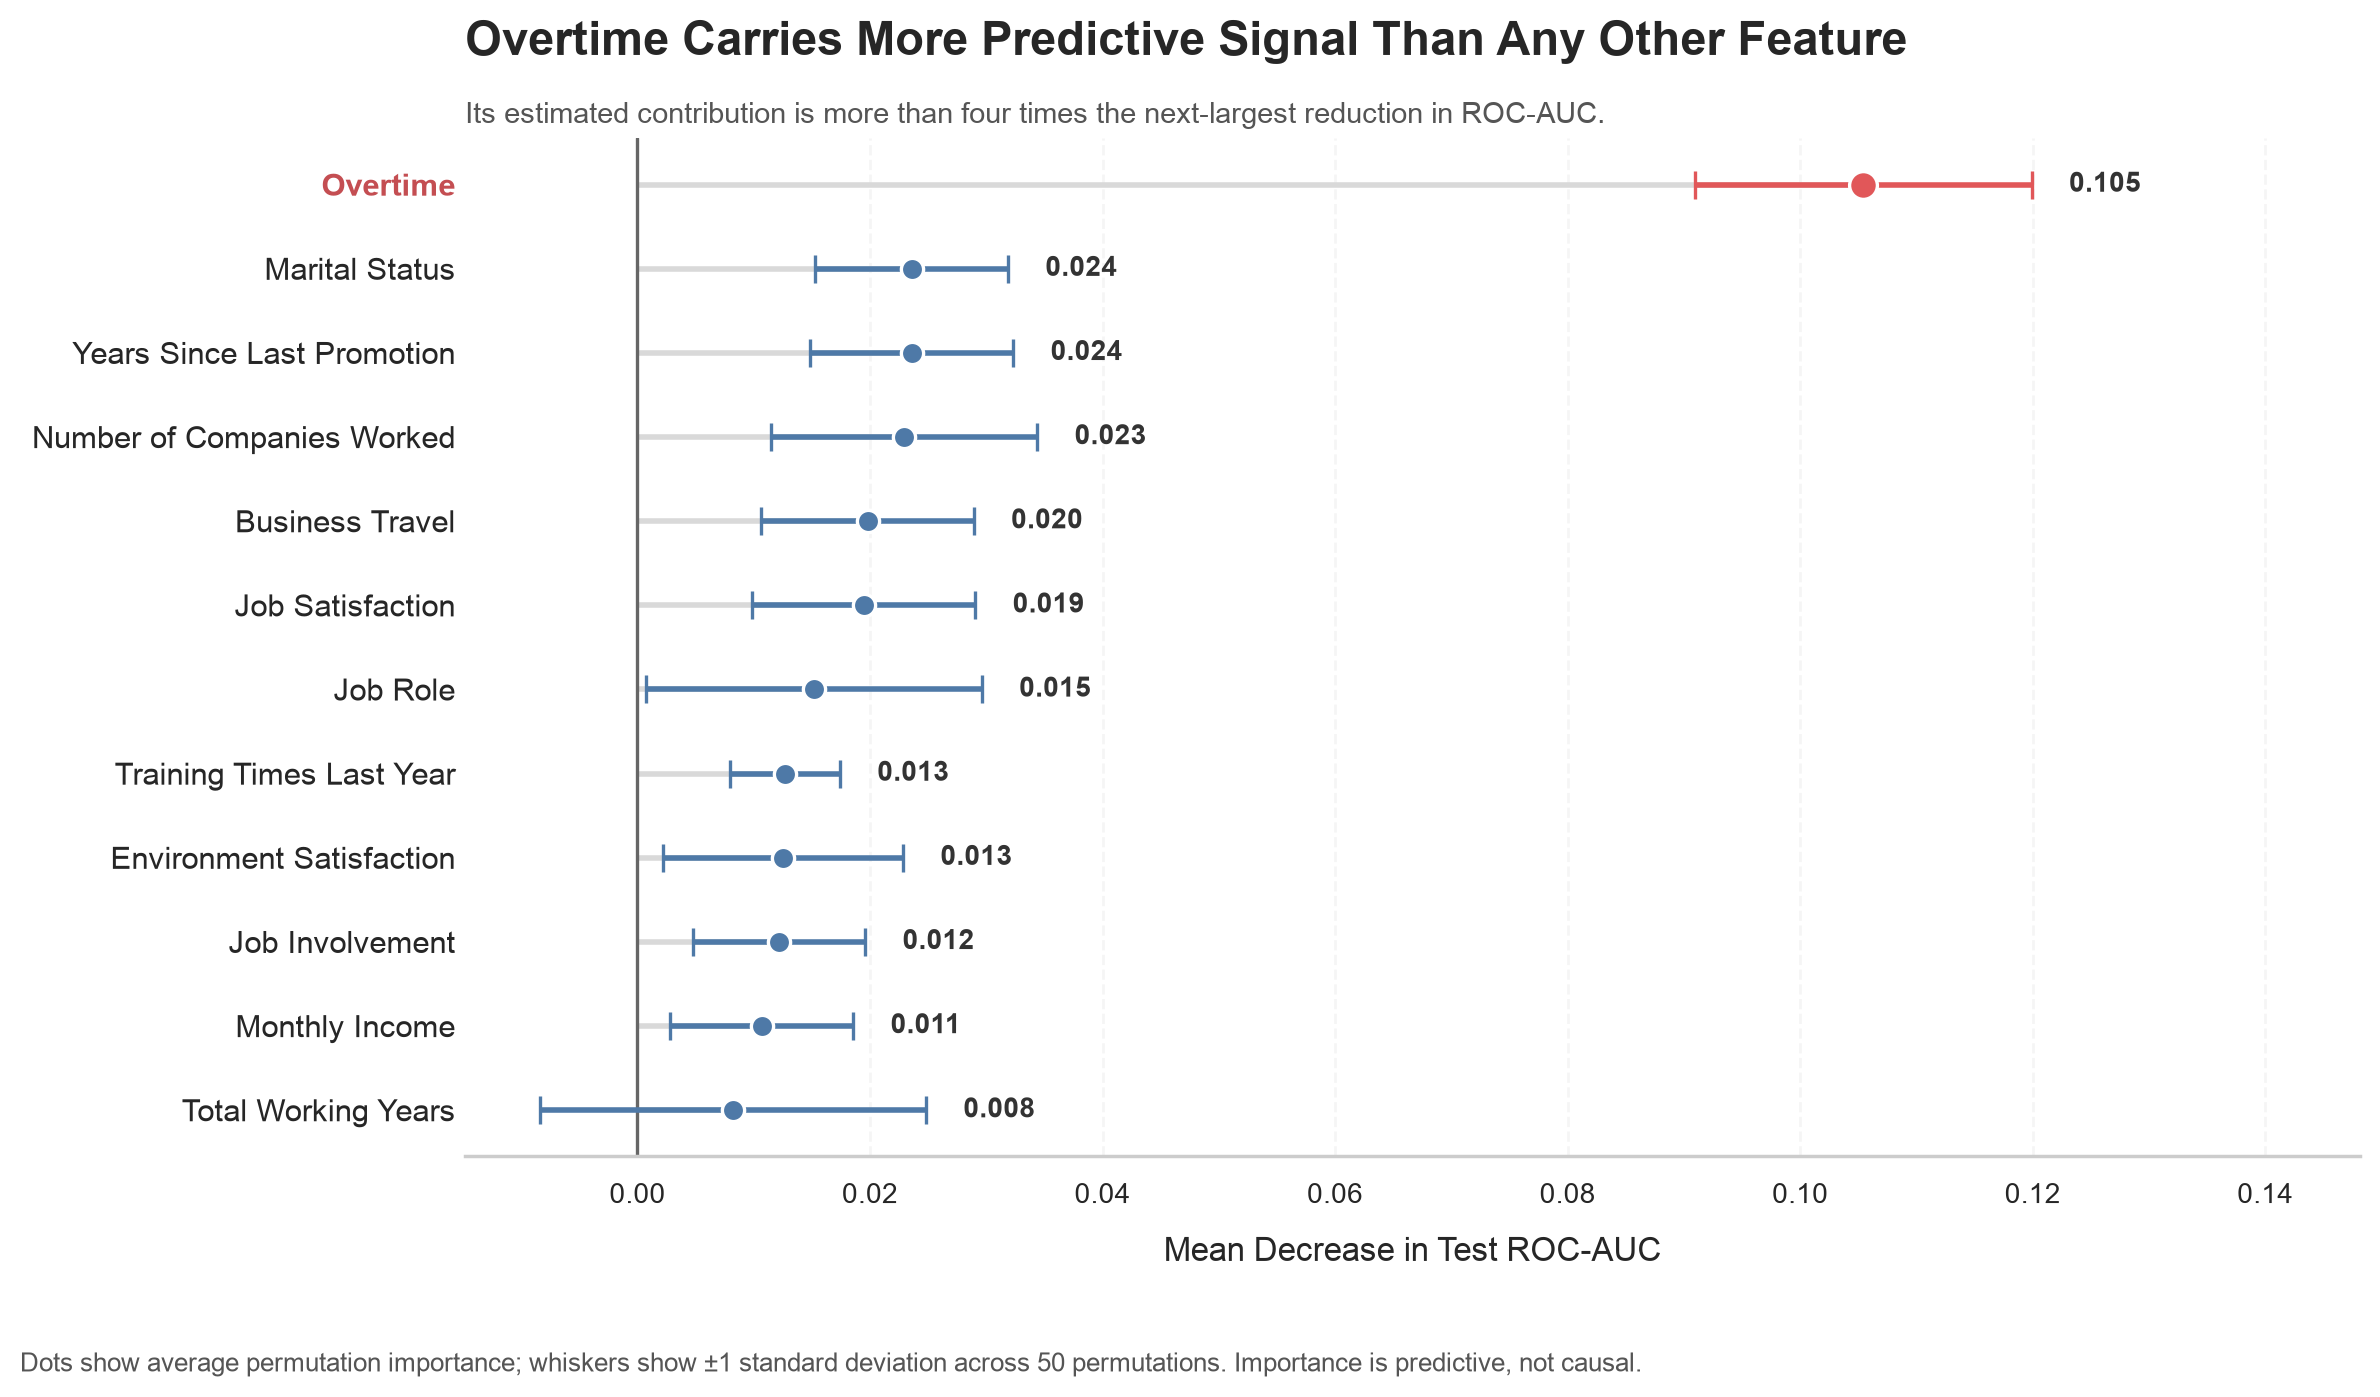

In [21]:
# I use permutation importance on the complete fitted pipeline so each original predictor
# is evaluated by the change in test ROC-AUC when its values are shuffled.
from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    estimator=final_model,
    X=X_test,
    y=y_test,
    scoring="roc_auc",
    n_repeats=50,
    random_state=42,
    n_jobs=1,
)

feature_importance = (
    pd.DataFrame({
        "Predictor": X_test.columns,
        "Mean Decrease in ROC-AUC": permutation_results.importances_mean,
        "Standard Deviation": permutation_results.importances_std,
    })
    .sort_values("Mean Decrease in ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

# I am selecting the twelve predictors with the largest
# average contribution to test-set ROC-AUC.
print("Permutation importance on the untouched test set:")
display(
    feature_importance.head(12).style.format({
        "Mean Decrease in ROC-AUC": "{:.3f}",
        "Standard Deviation": "{:.3f}",
    })
)

importance_plot = feature_importance.head(12).copy()

# I am replacing technical field names with readable labels
# so the visualization is understandable without reading the code.
predictor_labels = {
    "OverTime": "Overtime",
    "MaritalStatus": "Marital Status",
    "YearsSinceLastPromotion": "Years Since Last Promotion",
    "NumCompaniesWorked": "Number of Companies Worked",
    "BusinessTravel": "Business Travel",
    "JobSatisfaction": "Job Satisfaction",
    "JobRole": "Job Role",
    "TrainingTimesLastYear": "Training Times Last Year",
    "EnvironmentSatisfaction": "Environment Satisfaction",
    "JobInvolvement": "Job Involvement",
    "MonthlyIncome": "Monthly Income",
    "TotalWorkingYears": "Total Working Years"
}

importance_plot["Display Predictor"] = (
    importance_plot["Predictor"]
    .replace(predictor_labels)
)

# I am arranging the predictors from lowest to highest so the
# strongest feature appears naturally at the top of the chart.
importance_plot = (
    importance_plot
    .sort_values(
        "Mean Decrease in ROC-AUC",
        ascending=True
    )
    .reset_index(drop=True)
)

y_positions = np.arange(len(importance_plot))

importance_means = importance_plot[
    "Mean Decrease in ROC-AUC"
].to_numpy()

importance_deviations = importance_plot[
    "Standard Deviation"
].to_numpy()

# I am calculating flexible axis limits so uncertainty intervals
# and value labels remain fully visible.
minimum_endpoint = np.minimum(
    0,
    importance_means - importance_deviations
).min()

maximum_endpoint = (
    importance_means + importance_deviations
).max()

plotting_range = maximum_endpoint - minimum_endpoint

x_axis_minimum = minimum_endpoint - (plotting_range * 0.05)
x_axis_maximum = maximum_endpoint + (plotting_range * 0.22)

fig, ax = plt.subplots(
    figsize=(12, 7.5),
    dpi=200
)

# I am adding light connecting lines to help the reader compare
# each predictor's contribution with zero.
ax.hlines(
    y=y_positions,
    xmin=0,
    xmax=importance_means,
    color="#D9D9D9",
    linewidth=2,
    zorder=1
)

# I am plotting each predictor separately so Overtime can be
# highlighted while the remaining predictors use a consistent color.
for position, row in importance_plot.iterrows():

    is_overtime = row["Predictor"] == "OverTime"

    point_color = (
        "#E15759"
        if is_overtime
        else "#4E79A7"
    )

    ax.errorbar(
        x=row["Mean Decrease in ROC-AUC"],
        y=position,
        xerr=row["Standard Deviation"],
        fmt="o",
        color=point_color,
        ecolor=point_color,
        markersize=10 if is_overtime else 8,
        markeredgecolor="white",
        markeredgewidth=1.2,
        elinewidth=2,
        capsize=5,
        zorder=3
    )

    # I am positioning each value beyond its uncertainty interval
    # so the label cannot collide with the marker or error bar.
    label_position = (
        row["Mean Decrease in ROC-AUC"]
        + row["Standard Deviation"]
        + plotting_range * 0.025
    )

    ax.text(
        label_position,
        position,
        f"{row['Mean Decrease in ROC-AUC']:.3f}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color="#333333"
    )

# I am marking zero because an interval crossing zero indicates
# that the estimated contribution is less stable.
ax.axvline(
    x=0,
    color="#666666",
    linewidth=1.2,
    zorder=2
)

ax.set_yticks(
    y_positions,
    labels=importance_plot["Display Predictor"]
)

# I am emphasizing the Overtime label to connect it with the red marker.
for tick_label in ax.get_yticklabels():

    if tick_label.get_text() == "Overtime":
        tick_label.set_color("#C44E52")
        tick_label.set_fontweight("bold")

ax.set_xlim(
    x_axis_minimum,
    x_axis_maximum
)

ax.set_title(
    "Overtime Carries More Predictive Signal Than Any Other Feature",
    fontsize=17,
    fontweight="bold",
    loc="left",
    pad=30
)

ax.text(
    0,
    1.015,
    "Its estimated contribution is more than four times the next-largest reduction in ROC-AUC.",
    transform=ax.transAxes,
    fontsize=10.5,
    color="#555555"
)

ax.set_xlabel(
    "Mean Decrease in Test ROC-AUC",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel("")

ax.xaxis.grid(
    linestyle="--",
    alpha=0.18
)

ax.yaxis.grid(False)

ax.tick_params(
    axis="y",
    labelsize=11,
    length=0
)

ax.tick_params(
    axis="x",
    labelsize=10
)

sns.despine(
    left=True,
    bottom=False
)

fig.text(
    0.01,
    0.015,
    "Dots show average permutation importance; whiskers show ±1 standard deviation "
    "across 50 permutations. Importance is predictive, not causal.",
    fontsize=9.5,
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.06, 1, 0.94]
)

plt.show()


### Interpretation
Overtime is clearly the model’s most influential predictor. Shuffling Overtime reduced test ROC-AUC by 0.105 on average, more than four times the reduction associated with Marital Status or Years Since Last Promotion. Its uncertainty interval also remains well above zero, showing that the result is stable across the 50 permutations. Most remaining predictors contributed smaller and less certain amounts, while the interval for Total Working Years crossed zero. These results show which variables the model relies on for prediction, but they do not prove that any variable causes attrition.

## 8. Conclusion and Recommendations

This analysis shows that employee attrition can be predicted meaningfully, although not perfectly, from the available workplace and employee characteristics. I began with 1,470 employee records and removed only three constant fields and one identifier. No observations were removed, and the final modeling data contained 30 predictors with no missing values or duplicate records. Because only 16.12% of employees left, I used a stratified training and test split and evaluated the models with balanced metrics instead of relying only on accuracy.

I compared Logistic Regression and Random Forest against a non-predictive baseline using five-fold cross-validation on the training data. Logistic Regression produced the strongest validation performance, with a mean ROC-AUC of 0.827 and a mean PR-AUC of 0.605. It also identified a larger proportion of employees who left than Random Forest, making it the more appropriate model when the goal is to recognize potential attrition risk early.

On the untouched test set, Logistic Regression achieved a ROC-AUC of 0.802 and a PR-AUC of 0.557. The model identified 30 of the 47 employees who left, resulting in recall of 63.8%. However, it also incorrectly flagged 56 employees who stayed, which reduced precision to 34.9%. This tradeoff is important. The model can help identify employees who may need additional attention, but it cannot determine with certainty who will leave.

Overtime was the model’s dominant predictive feature. Shuffling Overtime reduced test ROC-AUC by approximately 0.105, more than four times the decrease associated with the next most influential predictors. Marital Status, Years Since Last Promotion, Number of Companies Worked, Business Travel, and Job Satisfaction also contributed to the model, although their estimated importance was smaller and less stable. These findings are predictive associations and should not be interpreted as proof that any individual factor causes an employee to leave.

I would use this model as an early-warning and workforce-planning tool rather than an automated decision system. Employees identified as higher risk should not be penalized or treated as if their departure is inevitable. Instead, the results could support voluntary check-ins, workload reviews, career-development conversations, and closer examination of overtime expectations, travel demands, job satisfaction, and promotion opportunities.

Before this model is used in practice, I recommend validating it with newer organizational data, evaluating performance across departments and demographic groups, and selecting a probability threshold that reflects the organization’s ability to respond to alerts. The model should also be monitored for changing performance over time. Its recall confidence interval ranges from approximately 48.9% to 76.6%, and only 47 departure cases were available in the test set, so the reported performance still contains meaningful uncertainty.

My conclusion is not that the model knows who will leave. Instead, it provides a structured way to identify patterns that may otherwise be overlooked. Used responsibly and alongside human judgment, it could help an organization ask better questions earlier and focus retention efforts where additional support may be most valuable.

## References

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.

Han, J., Kamber, M., & Pei, J. (2022). *Data mining: Concepts and techniques* (4th ed.). Morgan Kaufmann.

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

IBM. (n.d.). *IBM HR analytics employee attrition and performance* [Data set]. Kaggle. https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning: With applications in Python*. Springer. https://doi.org/10.1007/978-1-0716-1418-1

McKinney, W. (2022). *Python for data analysis: Data wrangling with pandas, NumPy, and Jupyter* (3rd ed.). O’Reilly Media.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

Waskom, M. L. (2021). Seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021